# 2) EDA Completo

En este apartado realizamos una inspección técnica inicial para determinar la "arquitectura" del dataset y la calidad de la información antes de proceder a la división de los datos

## 2.1 Carga de Datos e Inspección general


In [233]:
import pandas as pd

# Cargamos el dataset principal, es decir, el que entrenaremos.
# En nuestro caso, la suma de los dos últimos dígitos de uno de nosotros es 3, por lo que isaremos bank_03.pkl.
try:
    df_entreno = pd.read_pickle("banks/bank_03.pkl")
    print("Datos de entrenamiento cargados correctamente. Dimensiones:", df_entreno.shape)

    # Mostrar las primeras 5 filas para echar un vistazo
    display(df_entreno.head())
except FileNotFoundError:
    print("No se encontró el archivo.")

print("-" * 50)

# Cargamos el dataset de la competición
try:
    df_competicion = pd.read_pickle("banks/bank_competition.pkl")
    print("Datos de la competición cargados correctamente. Dimensiones:", df_competicion.shape)
    display(df_competicion.head())
except FileNotFoundError:
    print("No se encontró el archivo de competición.")

Datos de entrenamiento cargados correctamente. Dimensiones: (11000, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,None,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


--------------------------------------------------
Datos de la competición cargados correctamente. Dimensiones: (162, 16)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome
5553,43,management,married,tertiary,no,78,yes,no,cellular,21,nov,36,1,109,1,other
915,34,housemaid,married,secondary,no,0,yes,no,unknown,30,oct,154,1,-1,0,unknown
7652,54,technician,married,secondary,no,3323,yes,yes,cellular,8,apr,59,3,-1,0,unknown
5065,43,blue-collar,single,primary,no,-399,no,yes,cellular,28,jul,662,3,-1,0,unknown
3338,35,blue-collar,married,secondary,no,262,no,no,cellular,15,mar,427,1,181,3,success


Nos encontramos ante un problema de Clasificación Binaria, donde el objetivo es predecir si un cliente suscribirá (yes) o no (no) un depósito bancario (variable deposit)

## 2.2 Inspección general de datasets (Data Quality)

In [234]:
import pandas as pd
import numpy as np

# Cargamos el archivo del dataset de entrenamiento y obtenemos filas y columnas.
df = pd.read_pickle("banks/bank_03.pkl")

print("1. FORMA DEL DATASET\n")
print(f"Instancias (filas): {df.shape[0]}")
print(f"Variables (columnas): {df.shape[1]}")

print("\n2. TIPO DE VARIABLES\n")
# Separamos variables numéricas de las categóricas/ordinales
numericas = df.select_dtypes(include=[np.number]).columns.tolist()
categoricas = df.select_dtypes(exclude=[np.number]).columns.tolist()
print(f"Numéricas ({len(numericas)}): {numericas}")
print(f"Categóricas/Ordinales ({len(categoricas)}): {categoricas}")

print("\n3. CATEGÓRICAS CON ALTA CARDINALIDAD (>10 valores únicos)\n")
for col in categoricas:
    n_unicos = df[col].nunique()
    if n_unicos > 10:
        print(f"La variable '{col}' tiene {n_unicos} valores únicos.")

print("\n4. VALORES FALTANTES (Nulos, 'unknown' y 'other')\n")

encontrados = False
# Revisamos todas las columnas
for col in df.columns:
    # Contamos los None
    cantidad_nulos = df[col].isna().sum()

    # Contamos cuántos 'unknown' y 'other' hay (solo en texto/categoría)
    cantidad_unknown = 0
    cantidad_other = 0
    if df[col].dtype == 'object' or hasattr(df[col].dtype, 'categories'):
        cantidad_unknown = (df[col] == 'unknown').sum()
        cantidad_other = (df[col] == 'other').sum()

    # Sumamos los tres para saber el total de información faltante en esa columna
    total_faltantes = cantidad_nulos + cantidad_unknown + cantidad_other

    # Si falta algún dato, lo imprimimos con su desglose
    if total_faltantes > 0:
        porcentaje = (total_faltantes / len(df)) * 100

        # Preparamos un texto para saber exactamente qué tipo de faltantes son
        detalles = []
        if cantidad_nulos > 0:
            detalles.append(f"{cantidad_nulos} nulos (None)")
        if cantidad_unknown > 0:
            detalles.append(f"{cantidad_unknown} 'unknown'")
        if cantidad_other > 0:
            detalles.append(f"{cantidad_other} 'other'")

        print(f"La variable '{col}' tiene {total_faltantes} valores faltantes ({porcentaje:.2f}%) -> " + " y ".join(detalles))
        encontrados = True

if not encontrados:
    print("No se encontraron valores faltantes, 'unknown' ni 'other'.")

print("\n5. FILAS DUPLICADAS, COLUMNAS CONSTANTES O DE ID\n")
num_duplicados = df.duplicated().sum()
if num_duplicados > 0:
    print(f"Se han encontrado {num_duplicados} filas exactamente idénticas.")
    print("-> Se deben eliminar para evitar sesgar el modelo y reducir el tamaño del dataset.")
else:
    print("No se encontraron filas duplicadas en el dataset.")
constantes_o_id = False
for col in df.columns:
    if df[col].nunique() == 1:
        print(f"Columna constante encontrada: '{col}'")
        constantes_o_id = True
    elif df[col].nunique() == len(df):
        print(f"Columna tipo ID encontrada (todos los valores distintos): '{col}'")
        constantes_o_id = True
if not constantes_o_id:
    print("No se encontraron columnas constantes ni columnas tipo ID.")

print("\n6. TIPO DE PROBLEMA Y BALANCEO\n")
print("Es un problema de CLASIFICACIÓN (predecir 'yes' o 'no' en deposit).")
print("Distribución de la clase objetivo:")
# normalize=True nos da el porcentaje en vez del recuento
print((df['deposit'].value_counts(normalize=True) * 100).round(2))


print("\n--- VOLUMETRÍA DE LA VARIABLE 'month' ---")
# Calculamos el porcentaje de representación de cada mes en el 100% de los datos
proporciones_mes = df['month'].value_counts(normalize=True) * 100
print(proporciones_mes.round(2).astype(str) + ' %')

# Creamos una alerta para los meses con menos del 3% de los datos
meses_minoritarios = proporciones_mes[proporciones_mes < 3].index.tolist()
print(f"\n[!] ALERTA ESTRUCTURAL:")
print(f"Los siguientes meses tienen una representación marginal (< 3%): {meses_minoritarios}")
print(" -> NOTA: Al tener tan pocas filas, estas categorías sufrirán mucha varianza estadística al hacer el Train/Test Split. Habrá que vigilar posibles 'espejismos' en el EDA Profundo.")

1. FORMA DEL DATASET

Instancias (filas): 11000
Variables (columnas): 17

2. TIPO DE VARIABLES

Numéricas (7): ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
Categóricas/Ordinales (10): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'deposit']

3. CATEGÓRICAS CON ALTA CARDINALIDAD (>10 valores únicos)

La variable 'job' tiene 12 valores únicos.
La variable 'month' tiene 12 valores únicos.

4. VALORES FALTANTES (Nulos, 'unknown' y 'other')

La variable 'job' tiene 68 valores faltantes (0.62%) -> 68 'unknown'
La variable 'marital' tiene 402 valores faltantes (3.65%) -> 402 nulos (None)
La variable 'education' tiene 494 valores faltantes (4.49%) -> 494 'unknown'
La variable 'contact' tiene 2309 valores faltantes (20.99%) -> 2309 'unknown'
La variable 'poutcome' tiene 8733 valores faltantes (79.39%) -> 8205 'unknown' y 528 'other'

5. FILAS DUPLICADAS, COLUMNAS CONSTANTES O DE ID

No se encontraron filas duplicadas en e

Tras cargar el dataset bank_03.pkl, el análisis de variables e instancias arroja los siguientes resultados:
1. **Forma del Dataset**: El conjunto de datos cuenta con 11.000 instancias (filas) y 17 variables (columnas).<br>
2. **Tipo de Variables**: Se identifican 7 variables numéricas (age, balance, day, duration, campaign, pdays, previous) y 10 variables categóricas/ordinales (job, marital, education, default, housing, loan, contact, month, poutcome, deposit).<br>
3. **Categóricas con Alta Cardinalidad**: Las variables job y month presentan 12 valores únicos cada una, superando el umbral de 10 especificado en el enunciado.<br>
4. **Valores Faltantes**: Se detecta información incompleta bajo etiquetas como unknown, other o nulos en: poutcome (79.39%), contact (20.99%), education (4.49%), marital (3.65%) y job (0.62%).<br>
5. **Filas Duplicadas, Columnas Constamtes o de ID**: No se han encontrado duplicados, columnas con un único valor constante ni identificadores únicos (IDs).<br>
6. **Tipo de Problema y Balanceo**: Es un problema de clasificación con una clase objetivo muy equilibrada (52.55% 'no' vs 47.45% 'yes'), lo que justifica el uso de stratify=y en el split pero descarta la necesidad de técnicas de remuestreo.<br>
7. **Análisis particular de pdays**: El 74.57% de los clientes tiene el valor -1 (no contactado). Se tratará mediante un transformador personalizado que genere una variable binaria y gestione el valor numérico por separado para no distorsionar las escalas.<br>
8. **Volumetría de la Variable month (ALERTA ESTRUCTURAL)**: Los meses de sep, mar y dec tienen una representación marginal inferior al 3%. Al tener tan pocas filas, estas categorías sufrirán mucha varianza estadística en el split, por lo que habrá que vigilar posibles "espejismos" en el EDA Profundo.

# Parte 3: Decisión de la Evaluación

## 3.1. Diseño de la Evaluación y Metodología
### 3.1.1 Semilla de Reproducibilidad
Para asegurar que todos los resultados sean 100% reproducibles y que siempren sean los mismos, fijaremos una semilla global (`random_state`). Esta semilla se ha calculado como la suma de los NIAs de ambos miembros del equipo.

In [235]:
import math
import pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import fbeta_score, make_scorer

# Importación experimental (requerida por Scikit-Learn para usar el Halving)
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV

print("1. CONFIGURACIÓN DE REPRODUCIBILIDAD\n")

# Semilla calculada como la suma de los NIAs del grupo
SEMILLA_NIA = 100522306
print(f"[+] Semilla global (random_state) fijada en: {SEMILLA_NIA}")


# Transformamos 'yes' en 1 y 'no' en 0
df['deposit_bin'] = df['deposit'].map({'yes': 1, 'no': 0})
# Separamos las variables predictoras (X) de la variable objetivo (y)
X = df.drop(columns=['deposit', 'deposit_bin'])
y = df['deposit_bin']
print(f"Dimensiones de X: {X.shape}")
print(f"Dimensiones de y: {y.shape}")

1. CONFIGURACIÓN DE REPRODUCIBILIDAD

[+] Semilla global (random_state) fijada en: 100522306
Dimensiones de X: (11000, 16)
Dimensiones de y: (11000,)


### 3.1.2 Selección de Métricas (Costes Asimétricos)
El contexto de negocio bancario nos plantea una situación con costes asimétricos: perder a un cliente interesado (Falso Negativo) supone una pérdida mucho mayor que hacer una llamada infructuosa (Falso Positivo).

* **Métrica Principal (Refit):** Haremos uso de **F2-Score**. Esta métrica guiará a los algoritmos priorizando la exhaustividad (*Recall*) para captar ventas, pero penalizando un exceso descontrolado de llamadas.
* **Métricas Secundarias:** También mediremos a la vez el **ROC-AUC** (capacidad matemática de separabilidad) y el **Accuracy** (interpretabilidad general).

In [236]:
print("3.1.2 CONFIGURACIÓN DE MÉTRICAS\n")

# Programamos el F2-Score manualmente (Scikit-Learn no lo incluye por defecto en texto)
f2_scorer = make_scorer(fbeta_score, beta=2)

# Diccionario con todas las métricas que se calcularán simultáneamente
scoring_metrics = {
    'f2_score': f2_scorer,
    'roc_auc': 'roc_auc',
    'accuracy': 'accuracy'
}

# Variable clave: le dirá a los algoritmos qué métrica mirar para elegir al ganador
metrica_principal = 'f2_score' 

print(f"[+] Métrica PRINCIPAL a maximizar: '{metrica_principal}'")
print("[+] Métricas SECUNDARIAS de control: 'roc_auc' y 'accuracy'")

3.1.2 CONFIGURACIÓN DE MÉTRICAS

[+] Métrica PRINCIPAL a maximizar: 'f2_score'
[+] Métricas SECUNDARIAS de control: 'roc_auc' y 'accuracy'


### 3.1.3 Evaluación Externa (Outer Evaluation)
Para la estimación del rendimiento futuro en producción, aplicaremos la técnica de **Holdout** . Dividiremos el *dataset* en **2/3 para Entrenamiento (Train) y 1/3 para Prueba (Test)**. 

Para garantizar la integridad estadística usaremos:
* **Aleatorización (`shuffle = True`):** Evitamos sesgos por la ordenación original del archivo.
* **Estratificación (`stratify = y`):** Aseguramos que tanto Train como Test mantengan exactamente la misma proporción de clientes que contratan  (~47.5%).

**Protocolo Anti-Data Leakage:** A partir de esta celda, el conjunto de *Test* ($X_{test}$) queda completamente aislado en una "caja fuerte". Todas las transformaciones y optimizaciones se ajustarán estrictamente sobre el conjunto de *Train*. 
La evaluación final del modelo sobre el conjunto de *Test* se visualizará mediante una **Matriz de Confusión** para cuantificar el impacto real en el negocio.

In [237]:
print("2. EVALUACIÓN EXTERNA (OUTER)\n")

# Partición estricta: 2/3 Train, 1/3 Test con estratificación y aleatorización
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=1/3, 
    random_state=SEMILLA_NIA, 
    shuffle=True,
    stratify=y
)

# Creamos el dataset temporal EXCLUSIVO para el EDA Profundo (solo Train)
df_train = pd.concat([X_train, y_train], axis=1)

print("[+] Partición Holdout realizada con éxito:")
print(f"    - Train (Entrenamiento y HPO): {X_train.shape[0]} instancias")
print(f"    - Test  (Test final aislado): {X_test.shape[0]} instancias")

2. EVALUACIÓN EXTERNA (OUTER)

[+] Partición Holdout realizada con éxito:
    - Train (Entrenamiento y HPO): 7333 instancias
    - Test  (Test final aislado): 3667 instancias


### 3.1.4 Evaluación Interna (Inner Evaluation)
La evaluación interna se ejecutará exclusivamente sobre el conjunto de Entrenamiento para la optimización de hiperparámetros (HPO) y selección de modelos.

Emplearemos un **Stratified K-Fold con $k=5$** . Esto nos asegura que en cada uno de los 5 pliegues iterativos de validación se respete el balance original de las clases, evitando que el azar en las particiones engañe al optimizador.

In [238]:
print("3.1.4 EVALUACIÓN INTERNA (INNER)\n")

# Configuramos la partición interna K=5 para la búsqueda de hiperparámetros
kf_inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA_NIA)
print("[+] Estrategia configurada: Stratified K-Fold (k=5)")

3.1.4 EVALUACIÓN INTERNA (INNER)

[+] Estrategia configurada: Stratified K-Fold (k=5)


### 3.1.5 Motor de Búsqueda Avanzada (Successive Halving)
Anticipando la altísima complejidad temporal ($O(n^2)$) de las Máquinas de Vectores de Soporte (SVM) que entrenaremos posteriormente, descartamos el uso de fuerza bruta (`GridSearchCV`). 

Implementaremos una Búsqueda por Torneos: **Successive Halving (`HalvingGridSearchCV`)**.
* **Recurso (`resource`):** Limitaremos dinámicamente el número de filas (`n_samples`).
* **Factor de eliminación:** Usaremos el Número de Euler ($e \approx 2.71828$). Matemáticamente, es la proporción más eficiente para ir filtrando y eliminando los hiperparámetros que no funcionan bien en cada fase del entrenamiento.
* **Recursos iniciales (`min_resources`):** Se ajusta a `'exhaust'` para garantizar por ingeniería inversa que los finalistas del torneo se entrenen con el 100% del conjunto de *Train*.

In [239]:
print("3.1.5. PARÁMETROS MAESTROS DEL OPTIMIZADOR (HPO)\n")

# Guardamos la configuración maestra en un diccionario para inyectarlo 
# de forma limpia en los pipelines de los siguientes apartados.
config_halving = {
    'factor': math.e,               # Eliminación basada en el Número de Euler (~2.718)
    'resource': 'n_samples',        # Aumentar progresivamente las filas del dataset
    'min_resources': 'exhaust',     # Forzar el uso del 100% de datos en la ronda final
    'cv': kf_inner,                 # Inyectamos nuestra validación K=5
    'scoring': scoring_metrics,     # Evaluar las 3 métricas
    'refit': metrica_principal,     # Escoger al ganador basándose en el F2-Score
    'random_state': SEMILLA_NIA,    # Misma selección aleatoria en rondas iniciales
    'n_jobs': -1                    # Paralelización masiva (todos los núcleos)
}

print("[+] Motor HPO preparado: Successive Halving")
print(f"    - Factor de eliminación: e ({math.e:.5f})")
print("    - Configuración guardada en el diccionario 'config_halving'")

3.1.5. PARÁMETROS MAESTROS DEL OPTIMIZADOR (HPO)

[+] Motor HPO preparado: Successive Halving
    - Factor de eliminación: e (2.71828)
    - Configuración guardada en el diccionario 'config_halving'


## 3.2 EDA Profundo

### 3.2.1 Análisis Univariante: Distribuciones y Asimetría

In [240]:
import numpy as np
import pandas as pd

print("3.3.1 ANÁLISIS DE ASIMETRÍA (SKEWNESS)\n")

# 1. Inicializamos las listas vacías que guardarán la decisión
columnas_asim = []
columnas_sim = []

# Asumimos que la lista 'numericas' ya la tienes definida en tu notebook con las variables numéricas
for col in numericas: 
    asimetria = df_train[col].skew()
    
    # Lógica de decisión automatizada para asimetría
    if abs(asimetria) > 1:
        print(f"[-] {col}: Asimetría ALTA ({asimetria:.2f}). \n    -> DECISIÓN: Enviar a lista 'columnas_asim'.")
        columnas_asim.append(col)
    elif abs(asimetria) > 0.5:
        print(f"[-] {col}: Asimetría MEDIA ({asimetria:.2f}). \n    -> DECISIÓN: Enviar a lista 'columnas_asim' por precaución.")
        columnas_asim.append(col)
    else:
        print(f"[+] {col}: Bastante Simétrica ({asimetria:.2f}). \n    -> DECISIÓN: Enviar a lista 'columnas_sim'.")
        columnas_sim.append(col)

print("\n" + "="*50)
print("RESUMEN DE VARIABLES GUARDADAS EN MEMORIA PARA EL PIPELINE (4.1):")
print(f"Asimétricas (Se les aplicará Yeo-Johnson): {columnas_asim}")
print(f"Simétricas (Pasarán intactas al escalador): {columnas_sim}")
print("="*50)

3.3.1 ANÁLISIS DE ASIMETRÍA (SKEWNESS)

[-] age: Asimetría MEDIA (0.87). 
    -> DECISIÓN: Enviar a lista 'columnas_asim' por precaución.
[-] balance: Asimetría ALTA (8.12). 
    -> DECISIÓN: Enviar a lista 'columnas_asim'.
[+] day: Bastante Simétrica (0.10). 
    -> DECISIÓN: Enviar a lista 'columnas_sim'.
[-] duration: Asimetría ALTA (2.11). 
    -> DECISIÓN: Enviar a lista 'columnas_asim'.
[-] campaign: Asimetría ALTA (4.83). 
    -> DECISIÓN: Enviar a lista 'columnas_asim'.
[-] pdays: Asimetría ALTA (2.41). 
    -> DECISIÓN: Enviar a lista 'columnas_asim'.
[-] previous: Asimetría ALTA (8.14). 
    -> DECISIÓN: Enviar a lista 'columnas_asim'.

RESUMEN DE VARIABLES GUARDADAS EN MEMORIA PARA EL PIPELINE (4.1):
Asimétricas (Se les aplicará Yeo-Johnson): ['age', 'balance', 'duration', 'campaign', 'pdays', 'previous']
Simétricas (Pasarán intactas al escalador): ['day']


En este apartado analizamos la asimetría de las variables, descubriendo que la mayoría de las variables son altamentes asimétricas. Por esto, decidimos aplicar la transformación de Yeo-Johnson que, tras investigar, descubrimos que es el estándar porque al aplicar una transformación logarítmica, hace uso de una variable Lambda que ajusta a cada caso concreto para conseguir que la distribución se asemeje lo máximo posible a la Campana de Gauss. Las transformaciones serán apliacadas posteriormente en el apartado 4 haciendo uso de pipes

### 3.2.2 Casos Especiales (Feature Engineering)

#### -> El caso de la variable 'pdays'

In [241]:
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency

print(" ANÁLISIS PROFUNDO DE LA VARIABLE 'pdays' \n")

# 1. ANÁLISIS DESCRIPTIVO BÁSICO
print("1. DISTRIBUCIÓN Y PESO DEL VALOR ANÓMALO (-1):")
porcentaje_pdays_menos1 = (df_train['pdays'] == -1).mean() * 100

if porcentaje_pdays_menos1 > 0:
    print(f"  [!] ALERTA: El {porcentaje_pdays_menos1:.2f}% de los clientes tiene valor -1.")
    print("      Esto indica que la inmensa mayoría nunca ha sido contactada en campañas anteriores.")
else:
    print("  [+] No se detectaron valores -1 en la variable pdays.")

print("\n  - Resumen estadístico global de 'pdays':")
desc = df_train['pdays'].describe()
# Formateamos el describe para que sea visualmente más limpio en consola
print(f"    Media: {desc['mean']:.2f} | Desviación Std: {desc['std']:.2f} | Min: {desc['min']} | Max: {desc['max']}")


# 2. VALIDACIÓN ESTADÍSTICA (Test Chi-Cuadrado)
print("\n2. EVALUACIÓN ESTADÍSTICA DE INGENIERÍA DE CARACTERÍSTICAS:")
# Creamos temporalmente la variable binaria para evaluar su utilidad matemática
df_train['contactado_previamente'] = (df_train['pdays'] != -1).astype(int)

# Cruzamos la nueva variable binaria con la decisión de contratar el depósito
contingency_pdays = pd.crosstab(df_train['contactado_previamente'], df_train['deposit_bin'])
chi2_pdays, p_pdays, _, _ = chi2_contingency(contingency_pdays)

es_significativo = p_pdays < 0.05
print(f"  - P-value de la nueva variable ('contactado_previamente'): {p_pdays:.2e} -> {'SIGNIFICATIVO\n' if es_significativo else 'NO SIGNIFICATIVO/n'}")


# 3. VEREDICTO FINAL PARA EL PIPELINE
print(" INSTRUCCIONES FINALES PARA EL PIPELINE DE PREPROCESADO\n")

if es_significativo:
    print("[COLUMNA 'pdays']: APLICAR EXTRACCIÓN Y TRANSFORMACIÓN AVANZADA.")
    print(f" -> Motivo: Separar a los clientes 'nunca contactados' (-1) del resto es ALTAMENTE predictivo (p < 0.05).")
    print(" -> Acción para el Pipeline: Crear un CustomTransformer que:")
    print("    1. Genere la nueva variable binaria 'contactado_previamente' (0 si es -1, 1 si no).")
    print("    2. Reemplace el -1 en la columna original de 'pdays' por un valor lógico (ej. la mediana de los sí contactados) para no distorsionar la escala espacial de los modelos numéricos.")
else:
    print("[COLUMNA 'pdays']: MANTENER SIN TRANSFORMACIÓN BINARIA.")
    print(f" -> Motivo: La separación de los no contactados no aporta información extra significativa (p >= 0.05).")
    print(" -> Acción para el Pipeline: Dejar el valor numérico tal cual (aunque el -1 distorsione ligeramente la escala).")

# Limpiamos la columna temporal creada para no ensuciar el dataset principal aún
df_train = df_train.drop(columns=['contactado_previamente'])

 ANÁLISIS PROFUNDO DE LA VARIABLE 'pdays' 

1. DISTRIBUCIÓN Y PESO DEL VALOR ANÓMALO (-1):
  [!] ALERTA: El 74.39% de los clientes tiene valor -1.
      Esto indica que la inmensa mayoría nunca ha sido contactada en campañas anteriores.

  - Resumen estadístico global de 'pdays':
    Media: 51.58 | Desviación Std: 108.07 | Min: -1.0 | Max: 842.0

2. EVALUACIÓN ESTADÍSTICA DE INGENIERÍA DE CARACTERÍSTICAS:
  - P-value de la nueva variable ('contactado_previamente'): 7.51e-91 -> SIGNIFICATIVO

 INSTRUCCIONES FINALES PARA EL PIPELINE DE PREPROCESADO

[COLUMNA 'pdays']: APLICAR EXTRACCIÓN Y TRANSFORMACIÓN AVANZADA.
 -> Motivo: Separar a los clientes 'nunca contactados' (-1) del resto es ALTAMENTE predictivo (p < 0.05).
 -> Acción para el Pipeline: Crear un CustomTransformer que:
    1. Genere la nueva variable binaria 'contactado_previamente' (0 si es -1, 1 si no).
    2. Reemplace el -1 en la columna original de 'pdays' por un valor lógico (ej. la mediana de los sí contactados) para no di

Aunque el guion indica que se debe realizar el preproceso de paydays en esta sección, hemos decidido no ejecutarlo aquí, sino integrarlo como un CustomTransformer dentro de los Pipelines de Scikit-Learn en el Apartado 4. Esto garantiza que no haya fugas de información (Data Leakage) y que las futuras predicciones se transformen de forma automática.

### 3.2.3 Categorías Raras (Rare Labels)

In [242]:
import pandas as pd
import numpy as np

print("EXTRA: ANÁLISIS MATEMÁTICO DE CATEGORÍAS RARAS (IGNORANDO NULOS/VACÍOS)\n")

# Definimos los umbrales matemáticos
umbral_frecuencia = 0.015  # Consideramos "rara" si aparece en menos del 1.5% de los datos válidos
umbral_diferencia = 0.10   # Diferencia del 10% respecto a la media para considerarla "predictiva"

# Lista de valores que indican datos incompletos o vacíos
valores_incompletos = ['unknown', 'nonexistent', 'other', '?', 'na', 'n/a', 'null', 'none', '-', '', ' ']


tasa_global = df_train['deposit_bin'].mean()
print(f"Tasa de conversión global del dataset: {tasa_global*100:.2f}%\n")

for col in categoricas:
    if col == 'deposit': continue

    # Ignoramos NaNs y valores de la lista 'valores_incompletos'
    # Pasamos a texto, minúsculas y quitamos espacios para hacer una búsqueda exacta
    col_limpia = df_train[col].astype(str).str.lower().str.strip()
    mask_validos = ~col_limpia.isin(valores_incompletos) & df_train[col].notna()

    df_validos = df_train[mask_validos]

    if len(df_validos) == 0:
        continue # Si toda la columna está vacía (improbable), pasamos a la siguiente

    # 2. Calculamos frecuencia SOLO sobre los válidos para saber cuáles podrían ser agrupadas
    frecuencias = df_validos[col].value_counts(normalize=True)
    categorias_raras = frecuencias[frecuencias < umbral_frecuencia].index.tolist()

    if len(categorias_raras) == 0:
        print(f"[{col}]: Ninguna categoría válida es menor al 1.5%. \n  -> DECISIÓN: No agrupar nada.\n")
        continue

    print(f"[{col}]: Entre los datos completos, podrían agruparse {categorias_raras} (frecuencia < 1.5%).")

    categorias_a_agrupar = []
    categorias_a_mantener = []

    # Análisis del impacto predictivo de cada categoría rara
    for cat in categorias_raras:
        # Tasa de éxito de esta categoría específica
        tasa_cat = df_validos[df_validos[col] == cat]['deposit_bin'].mean()
        diferencia = abs(tasa_cat - tasa_global)

        if diferencia > umbral_diferencia:
            categorias_a_mantener.append((cat, tasa_cat))
        else:
            categorias_a_agrupar.append((cat, tasa_cat))

    # Resultado final
    if len(categorias_a_agrupar) > 0:
        nombres_agrupar = [c[0] for c in categorias_a_agrupar]
        print(f"  -> DECISIÓN: SÍ AGRUPAR {nombres_agrupar}.")
        print(f"     ¿Por qué?: Son raras, no predictivas y hemos excluido los nulos del cálculo. Agruparlas en 'otros_agrupado' reducirá el ruido de los modelos.")

    if len(categorias_a_mantener) > 0:
        nombres_mantener = [c[0] for c in categorias_a_mantener]
        print(f"  -> DECISIÓN: NO AGRUPAR {nombres_mantener}.")
        for nombre, tasa in categorias_a_mantener:
            print(f"     ¿Por qué '{nombre}'?: Tasa del {tasa*100:.1f}% vs media global {tasa_global*100:.1f}%. Aporta demasiado valor predictivo como para camuflarla.")
    print("-" * 60)

EXTRA: ANÁLISIS MATEMÁTICO DE CATEGORÍAS RARAS (IGNORANDO NULOS/VACÍOS)

Tasa de conversión global del dataset: 47.46%

[job]: Ninguna categoría válida es menor al 1.5%. 
  -> DECISIÓN: No agrupar nada.

[marital]: Ninguna categoría válida es menor al 1.5%. 
  -> DECISIÓN: No agrupar nada.

[education]: Ninguna categoría válida es menor al 1.5%. 
  -> DECISIÓN: No agrupar nada.

[default]: Entre los datos completos, podrían agruparse ['yes'] (frecuencia < 1.5%).
  -> DECISIÓN: NO AGRUPAR ['yes'].
     ¿Por qué 'yes'?: Tasa del 25.0% vs media global 47.5%. Aporta demasiado valor predictivo como para camuflarla.
------------------------------------------------------------
[housing]: Ninguna categoría válida es menor al 1.5%. 
  -> DECISIÓN: No agrupar nada.

[loan]: Ninguna categoría válida es menor al 1.5%. 
  -> DECISIÓN: No agrupar nada.

[contact]: Ninguna categoría válida es menor al 1.5%. 
  -> DECISIÓN: No agrupar nada.

[month]: Entre los datos completos, podrían agruparse ['dec'

Hemos querido analizar la frecuencia de las variables categóricas para ver si habían algunas que podrían ser unificadas en caso de que su aparición fuera marginal para así eliminar ruido del dataset. Al final, esto solo ha ocurrido con 'dec' en la variable *month*. Sin embargo, al descubrir que aportaba demasiado valor predictivo no hemos podido camuflarla.

### 3.2.4 Estacionalidad y Espejismos Temporales

In [243]:
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency

print("ANÁLISIS TEMPORAL UNIFICADO (MES Y DÍA CON DETECCIÓN DE ESPEJISMOS)\n")



tasa_global = df_train['deposit_bin'].mean()

# Comprobación del sesgo temporal
print("1. ANÁLISIS DE SESGO TEMPORAL (Riesgo macroeconómico):")
if 'year' in df_train.columns:
    num_years = df_train['year'].nunique()
    if num_years == 1:
        sesgo_temporal = True
        print(f"  [!] ALERTA: Dataset de un solo año. Riesgo de estacionalidad engañosa.")
    else:
        sesgo_temporal = False
        print(f"  [+] OK: El dataset abarca {num_years} años. Patrones robustos.")
else:
    sesgo_temporal = True
    print("  [?] PRECAUCIÓN: No existe columna 'year'. Asumiremos riesgo de sesgo temporal.")


# Volumen vs. Éxito
print("\n2. ANÁLISIS DE ESPEJISMOS DE NEGOCIO:")

# Análisis del Mes 
stats_mes = df_train.groupby('month').agg(
    volumen=('deposit_bin', 'count'),
    tasa_exito=('deposit_bin', 'mean')
).reset_index()
stats_mes['pct_volumen'] = (stats_mes['volumen'] / len(df_train)) * 100
mes_estrella = stats_mes.loc[stats_mes['tasa_exito'].idxmax()]

mes_anomalo = None
if mes_estrella['pct_volumen'] < 5.0:
    mes_anomalo = mes_estrella['month']
    print(f"  [!] ESPEJISMO DETECTADO (MES): '{mes_anomalo}' tiene éxito anormal ({mes_estrella['tasa_exito']*100:.1f}%) pero bajísimo volumen ({mes_estrella['pct_volumen']:.1f}%).")
else:
    print(f"  [+] MES ESTRELLA FIABLE: '{mes_estrella['month']}' con {mes_estrella['tasa_exito']*100:.1f}% de éxito y buen volumen ({mes_estrella['pct_volumen']:.1f}%).")

# Análisis del Día
dia_anomalo = None
if 'day' in df_train.columns:
    stats_dia = df_train.groupby('day').agg(
        volumen=('deposit_bin', 'count'),
        tasa_exito=('deposit_bin', 'mean')
    ).reset_index()
    stats_dia['pct_volumen'] = (stats_dia['volumen'] / len(df_train)) * 100
    dia_estrella = stats_dia.loc[stats_dia['tasa_exito'].idxmax()]

    # Umbral más bajo para el día porque hay 31 posibles valores (Media ~3.2%)
    if dia_estrella['pct_volumen'] < 1.0:
        dia_anomalo = dia_estrella['day']
        print(f"  [!] ESPEJISMO DETECTADO (DÍA): El día '{dia_anomalo}' tiene éxito anormal ({dia_estrella['tasa_exito']*100:.1f}%) pero bajísimo volumen ({dia_estrella['pct_volumen']:.1f}%).")
    else:
        print(f"  [+] DÍA ESTRELLA FIABLE: El día '{dia_estrella['day']}' con {dia_estrella['tasa_exito']*100:.1f}% de éxito y volumen normal ({dia_estrella['pct_volumen']:.1f}%).")


# Validación con el test Chi-cuadrado
print("\n3. VALIDACIÓN ESTADÍSTICA (Test Chi-Cuadrado sobre el resto de datos):")

# A. Para el mes (Aislando el mes anómalo si existe)
df_mes_test = df_train[df_train['month'] != mes_anomalo] if mes_anomalo else df_train
contingency_month = pd.crosstab(df_mes_test['month'], df_mes_test['deposit_bin'])
_, p_value_m, _, _ = chi2_contingency(contingency_month)
estacionalidad_mes_real = p_value_m < 0.05
print(f"  - P-value Meses restantes: {p_value_m:.4f} -> {'SIGNIFICATIVO (Mantener)\n' if estacionalidad_mes_real else 'NO SIGNIFICATIVO (Borrar)\n'}")

# B. Para el día (Aislando el día anómalo si existe)
if 'day' in df_train.columns:
    df_dia_test = df_train[df_train['day'] != dia_anomalo] if dia_anomalo else df_train
    contingency_day = pd.crosstab(df_dia_test['day'], df_dia_test['deposit_bin'])
    _, p_value_d, _, _ = chi2_contingency(contingency_day)
    estacionalidad_dia_real = p_value_d < 0.05
    print(f"  - P-value Días restantes: {p_value_d:.4f} -> {'SIGNIFICATIVO (Mantener)\n' if estacionalidad_dia_real else 'NO SIGNIFICATIVO (Borrar)\n'}")


# Resultado final para el pipeline
print("INSTRUCCIONES FINALES PARA EL PIPELINE DE PREPROCESADO\n")

# Decisiones sobre el mes
if mes_anomalo and estacionalidad_mes_real:
    print(f"[COLUMNA 'month']: MANTENER COLUMNA. Acción previa -> df = df[df['month'] != '{mes_anomalo}']")
elif mes_anomalo and not estacionalidad_mes_real:
    print(f"[COLUMNA 'month']: ELIMINAR COLUMNA (DROP). Todo el mes es ruido temporal sin '{mes_anomalo}'.")
elif not mes_anomalo and estacionalidad_mes_real:
    print(f"[COLUMNA 'month']: MANTENER COLUMNA INTACTA.")
else:
    print(f"[COLUMNA 'month']: ELIMINAR COLUMNA (DROP). No hay estacionalidad mensual.")

# Decisiones sobre el día
if 'day' in df_train.columns:
    if dia_anomalo and estacionalidad_dia_real:
        print(f"[COLUMNA 'day']: MANTENER COLUMNA. Acción previa -> df = df[df['day'] != {dia_anomalo}]")
    elif dia_anomalo and not estacionalidad_dia_real:
        print(f"[COLUMNA 'day']: ELIMINAR COLUMNA (DROP). Todo el día es ruido temporal sin '{dia_anomalo}'.")
    elif not dia_anomalo and estacionalidad_dia_real:
        print(f"[COLUMNA 'day']: MANTENER COLUMNA INTACTA.")
    else:
        print(f"[COLUMNA 'day']: ELIMINAR COLUMNA (DROP). No hay estacionalidad diaria.")


# ==============================================================================
# Ejecución de la limpieza temporal dinámica (SOLO EN TRAIN)
# ==============================================================================
if mes_anomalo is not None:
    print(f"\n[+] Ejecutando eliminación dinámica del espejismo: Borrando filas donde month == '{mes_anomalo}'")
    
    # 1. Filtramos en X_train e y_train
    mascara_train = X_train['month'] != mes_anomalo
    X_train = X_train[mascara_train]
    y_train = y_train[mascara_train]

    # 2. También lo borramos del df_train por coherencia para el resto del EDA
    df_train = df_train[df_train['month'] != mes_anomalo]
    
    print(f"    Nuevas dimensiones de X_train tras purgar '{mes_anomalo}': {X_train.shape}")
else:
    print("\n[+] No se detectó ningún mes anómalo. No se elimina ninguna fila por espejismo temporal.")

# Nota: Hacemos lo mismo para el día si lo consideramos necesario
if dia_anomalo is not None and not estacionalidad_dia_real:
    # Aquí iría el código para borrar el día si fuera el caso
    pass

ANÁLISIS TEMPORAL UNIFICADO (MES Y DÍA CON DETECCIÓN DE ESPEJISMOS)

1. ANÁLISIS DE SESGO TEMPORAL (Riesgo macroeconómico):
  [?] PRECAUCIÓN: No existe columna 'year'. Asumiremos riesgo de sesgo temporal.

2. ANÁLISIS DE ESPEJISMOS DE NEGOCIO:
  [!] ESPEJISMO DETECTADO (MES): 'dec' tiene éxito anormal (92.3%) pero bajísimo volumen (1.1%).
  [+] DÍA ESTRELLA FIABLE: El día '10.0' con 77.5% de éxito y volumen normal (1.4%).

3. VALIDACIÓN ESTADÍSTICA (Test Chi-Cuadrado sobre el resto de datos):
  - P-value Meses restantes: 0.0000 -> SIGNIFICATIVO (Mantener)

  - P-value Días restantes: 0.0000 -> SIGNIFICATIVO (Mantener)

INSTRUCCIONES FINALES PARA EL PIPELINE DE PREPROCESADO

[COLUMNA 'month']: MANTENER COLUMNA. Acción previa -> df = df[df['month'] != 'dec']
[COLUMNA 'day']: MANTENER COLUMNA INTACTA.

[+] Ejecutando eliminación dinámica del espejismo: Borrando filas donde month == 'dec'
    Nuevas dimensiones de X_train tras purgar 'dec': (7255, 16)


Aquí quisimos hacer una valoración de la posible agrupación por estaciones. Sin embargo, al encontrar esa gran variación desmedida respecto al número de llamadas hechas en diciembre, pensamos que podríamos estar ante un espejismo estadístico, lo que llevaría a una eliminación de la variable; al hacer una inspección más profunda del resto de meses, descubrimos que sí son significativos, por lo que solo eliminamos dec como extreme outlier que puede llegar a emperorar nuestras predicciones. Este mismo estudio lo hicimos para los días, pero no encontramos nada relevante.

### 3.2.5 Data Leakage en 'duration'

In [244]:
import pandas as pd
import numpy as np
from scipy.stats import pointbiserialr

print("3.2.5 ANÁLISIS DE DATA LEAKAGE EN 'duration'\n")

# 1. CÁLCULO DEL PODER PREDICTIVO ANÓMALO
correlaciones = {}
for col in numericas:
    # Ignoramos pdays por su -1 que distorsiona el cálculo lineal
    if col == 'pdays': continue 
    corr, _ = pointbiserialr(df_train[col], df_train['deposit_bin'])
    correlaciones[col] = abs(corr)

# Ordenamos para ver la variable más predictiva
correlaciones_ordenadas = sorted(correlaciones.items(), key=lambda x: x[1], reverse=True)

corr_duration = correlaciones.get('duration', 0)
# Obtenemos la mejor variable que NO sea duration para comparar
mejor_otra_var = next((item for item in correlaciones_ordenadas if item[0] != 'duration'), ("Ninguna", 0))

print(f"-> Correlación de 'duration' con la contratación: {corr_duration:.4f}")
print(f"-> Correlación de la siguiente mejor variable ({mejor_otra_var[0]}): {mejor_otra_var[1]:.4f}")

# 2. LÓGICA DE DECISIÓN AUTOMATIZADA
# Si la correlación es desproporcionadamente alta (> 0.35) y sabemos por negocio
# que es un dato capturado POSTERIORMENTE a la decisión, confirmamos el Leakage.
UMBRAL_LEAKAGE = 0.35 

if corr_duration > UMBRAL_LEAKAGE:
    print(f"\n[!] ALERTA CRÍTICA: La variable 'duration' tiene una correlación anormalmente alta.")
    print("    Matemáticamente dominará al modelo. Por lógica de negocio, este dato no existe ANTES de la llamada.")
    print("    DECISIÓN: ELIMINAR 'duration' para garantizar la honestidad predictiva del modelo.")
    
    # --- EJECUCIÓN DE LA ELIMINACIÓN SEGURA ---
    
    # 1. Eliminamos de los DataFrames principales (Train y Test)
    if 'duration' in X_train.columns:
        X_train = X_train.drop(columns=['duration'])
    if 'duration' in X_test.columns:
        X_test = X_test.drop(columns=['duration'])
    if 'duration' in df_train.columns:
        df_train = df_train.drop(columns=['duration'])
        
    # 2. Eliminamos de las listas de memoria (para que los Pipelines del Apdo. 4 no rompan)
    if 'duration' in numericas:
        numericas.remove('duration')
    if 'duration' in columnas_asim:
        columnas_asim.remove('duration')
    if 'duration' in columnas_sim:
        columnas_sim.remove('duration')
        
    print("\n[+] 'duration' purgada con éxito de X_train, X_test y listas de preprocesado.")
    print(f"    Nuevas dimensiones de X_train: {X_train.shape}")
    
else:
    print(f"\n[+] OK: La correlación de 'duration' ({corr_duration:.4f}) no es sospechosa.")
    print("    DECISIÓN: MANTENER la variable en el dataset.")

print("-" * 60)

3.2.5 ANÁLISIS DE DATA LEAKAGE EN 'duration'

-> Correlación de 'duration' con la contratación: 0.4526
-> Correlación de la siguiente mejor variable (previous): 0.1477

[!] ALERTA CRÍTICA: La variable 'duration' tiene una correlación anormalmente alta.
    Matemáticamente dominará al modelo. Por lógica de negocio, este dato no existe ANTES de la llamada.
    DECISIÓN: ELIMINAR 'duration' para garantizar la honestidad predictiva del modelo.

[+] 'duration' purgada con éxito de X_train, X_test y listas de preprocesado.
    Nuevas dimensiones de X_train: (7255, 15)
------------------------------------------------------------


Hemos descubierto en nuestro EDA una fuga de información en la variable "*duration*". Desde el punto de vista del banco, esta variable no tiene ninguna lógica atenderla, pues la decisión de si llamar o no a un posible cliente no tiene nada que ver con la duración, pues cuando tengamos que predecir si la próxima llamada llevará a un contrato no disponemos del dato de la duración de esta llamada futura, y cualquier llamada no tomada tiene duración 0; de esta manera, esto contamina el resultado del modelo respecto a los otros datos, haciendo que el modelo esté sesgado, inclinado más hacia el no. Sin embargo, vemos que si eliminamos la variable *duration* las métricas de exhaustividad sufren un desplome crítico que pone en riesgo los resultados del entrenamiento de nuestro modelo. Aún así, hemos decidido que es mejor tener un modelo con menos de F2-score, pero que sea un score real y no el ficticio inflado por valores de los que nos dispondremos como duration.

### 3.2.6 Correlación y Poder Predictivo Global

In [245]:
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency, pointbiserialr

print("1er EXTRA: Multicoleanidad \n")
# Calculamos la correlación de Pearson y buscamos pares altamente correlacionados
corr_matrix = df_train[numericas].corr().abs()
# Seleccionamos el triángulo superior de la matriz de correlación
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

colineales = [column for column in upper.columns if any(upper[column] > 0.8)]
if len(colineales) > 0:
    print(f"Alta correlación (>0.8) en: {colineales}")
    print("Eliminar una de las variables del par o aplicar regularización L1 (Lasso).")
else:
    print("No se detectó multicolinealidad severa (Pearson < 0.8). Los modelos serán estables.")


print("\n2do EXTRA: Importancia de Atributos")
print("Analizando qué variables tienen mayor poder predictivo sobre 'deposit'...")

print("\nVariables Numéricas (Correlación Punto-Biserial)")
for col in numericas:
    # Ignoramos pdays aquí porque -1 distorsiona la matemática, lo trataremos aparte
    if col == 'pdays': continue

    corr, p_value = pointbiserialr(df_train[col], df_train['deposit_bin'])
    if p_value < 0.05:
        fuerza = "ALTA" if abs(corr) > 0.3 else ("MODERADA" if abs(corr) > 0.1 else "BAJA")
        print(f"  - {col}: Fuerza predictiva (P-value): {fuerza} (r = {corr:.3f})")
    else:
        print(f"  - {col}: NO significativa (p-value >= 0.05). Se considera eliminar.")

print("\nVariables Categóricas (Test Chi-Cuadrado)")
for col in categoricas:
    if col == 'deposit': continue

    contingency_table = pd.crosstab(df_train[col], df_train['deposit_bin'])
    chi2, p_value, dof, expected = chi2_contingency(contingency_table)

    if p_value < 0.05:
        print(f"  - {col}: Relación significativa con la suscripción (p-value = {p_value:.2e}). Mantener en el modelo.")
    else:
        print(f"  - {col}: NO significativa. La distribución de esta variable es independiente de la suscripción. Podría generar ruido.")


1er EXTRA: Multicoleanidad 

No se detectó multicolinealidad severa (Pearson < 0.8). Los modelos serán estables.

2do EXTRA: Importancia de Atributos
Analizando qué variables tienen mayor poder predictivo sobre 'deposit'...

Variables Numéricas (Correlación Punto-Biserial)
  - age: Fuerza predictiva (P-value): BAJA (r = 0.039)
  - balance: Fuerza predictiva (P-value): BAJA (r = 0.078)
  - day: Fuerza predictiva (P-value): BAJA (r = -0.065)
  - campaign: Fuerza predictiva (P-value): MODERADA (r = -0.133)
  - previous: Fuerza predictiva (P-value): MODERADA (r = 0.148)

Variables Categóricas (Test Chi-Cuadrado)
  - job: Relación significativa con la suscripción (p-value = 4.78e-46). Mantener en el modelo.
  - marital: Relación significativa con la suscripción (p-value = 3.29e-14). Mantener en el modelo.
  - education: Relación significativa con la suscripción (p-value = 9.00e-15). Mantener en el modelo.
  - default: Relación significativa con la suscripción (p-value = 6.39e-06). Mantener 

# 4. Métodos Básicos: KNN y Árboles

En esta sección desarrollaremos y evaluaremos nuestros primeros modelos predictivos. Para garantizar la reproducibilidad, modularidad y prevenir la fuga de información (*Data Leakage*), encapsularemos todo el proceso dentro de **Pipelines de Scikit-Learn**.

## 4.1. Arquitectura de Preprocesamiento (Fase 0)
Vamos a usar una arquitectura en tres niveles:
1. **Transformador Personalizado (`PdaysTransformer`):** Una clase programada a medida que implementa la decisión de negocio tomada en el EDA: aislar a los clientes "nunca contactados" (pdays = -1) en una variable binaria y neutralizar el -1 sustituyéndolo por la mediana del resto de clientes.
2. **Transformador de Columnas (`ColumnTransformer`):** Un enrutador que aplicará *One-Hot Encoding* a las variables categóricas y dejará preparadas las numéricas para el escalado.
3. **Pipeline Maestro:** Unificará los pasos anteriores junto con el algoritmo predictivo final.

In [246]:
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PowerTransformer
from sklearn.neighbors import KNeighborsClassifier

print("4.1. CONSTRUCCIÓN DE LA ARQUITECTURA DE PIPELINES\n")

# 1. Transformador personalizado para 'pdays'
class PdaysTransformer(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.mediana_contactados_ = 0
        
    def fit(self, X, y=None):
        mask_contactados = X['pdays'] != -1
        if mask_contactados.sum() > 0:
            self.mediana_contactados_ = X.loc[mask_contactados, 'pdays'].median()
        else:
            self.mediana_contactados_ = 0
        return self
    
    def transform(self, X):
        X_trans = X.copy()
        X_trans['contactado_previamente'] = (X_trans['pdays'] != -1).astype(int)
        X_trans.loc[X_trans['pdays'] == -1, 'pdays'] = self.mediana_contactados_
        return X_trans

# 2. USO DE LAS LISTAS DINÁMICAS Y ENRUTAMIENTO
# [NUEVO] Inyectamos la nueva variable creada por el transformer en las listas simétricas
if 'contactado_previamente' not in columnas_sim:
    columnas_sim.append('contactado_previamente')

# Juntamos las listas dinámicas para tener el total de numéricas
columnas_numericas = columnas_asim + columnas_sim 
columnas_categoricas = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

# 3. TALLER DE PREPROCESADORES

# --- A) SUB-PIPELINE NUMÉRICO PARA KNN ---
transformador_asimetria = ColumnTransformer(
    transformers=[
        ('yeo', PowerTransformer(method='yeo-johnson'), columnas_asim)
    ],
    remainder='passthrough' 
)

pipeline_num_knn = Pipeline([
    ('corrector_asimetria', transformador_asimetria),
    ('scaler', 'passthrough') 
])

# --- B) ENSAMBLAJE FINAL DEL PREPROCESADOR KNN ---
preprocesador_knn = ColumnTransformer(
    transformers=[
        ('num', pipeline_num_knn, columnas_numericas), 
        # [NUEVO] sparse_output=False evita incompatibilidades de memoria con KNN
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False), columnas_categoricas)
    ],
    remainder='passthrough'
)

# --- C) PREPROCESADOR PARA ÁRBOLES (Neutro) ---
preprocesador_arboles = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', columnas_numericas), 
        # [NUEVO] Quitamos drop='first' porque los árboles necesitan ver todas las categorías explícitamente
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), columnas_categoricas)
    ],
    remainder='passthrough'
)

# Pipeline base definitivo para el modelo KNN
pipeline_knn = Pipeline([
    ('pdays_custom', PdaysTransformer()),        
    ('preprocesador', preprocesador_knn),            
    ('clasificador', KNeighborsClassifier())     
])

print(f"[+] 'PdaysTransformer' compilado.")
print(f"[+] Nueva variable 'contactado_previamente' enrutada correctamente al escalador.")
print(f"[+] Yeo-Johnson configurado dinámicamente para las {len(columnas_asim)} variables asimétricas.")
print(f"[+] Preprocesadores optimizados: KNN (Drop First) vs Árboles (All Categories).")
print(f"[+] Pipeline base preparado para el torneo de escaladores.")

4.1. CONSTRUCCIÓN DE LA ARQUITECTURA DE PIPELINES

[+] 'PdaysTransformer' compilado.
[+] Nueva variable 'contactado_previamente' enrutada correctamente al escalador.
[+] Yeo-Johnson configurado dinámicamente para las 5 variables asimétricas.
[+] Preprocesadores optimizados: KNN (Drop First) vs Árboles (All Categories).
[+] Pipeline base preparado para el torneo de escaladores.


## 4.2. Torneo de Métodos de Escalado para KNN (Fase 1)
Dado que KNN es un algoritmo basado en distancias espaciales, es muy sensible a la escala de las variables numéricas. El statement indica que se deben evaluar tres métodos de escalado: `MinMaxScaler`, `StandardScaler` y `RobustScaler`. 
En lugar de evaluarlos por separado, trataremos el paso de escalado como un hiperparámetro dentro de una validación cruzada (`GridSearchCV`), utilizando nuestra métrica brújula (**F2-Score**) para encontrar al escalador óptimo de forma automatizada y rigurosa.

**Nota de Diseño Analítico:**
> Basándonos en nuestro EDA, sabemos que la distribución y presencia de *outliers* varía mucho según la variable (por ejemplo, `balance` presenta valores extremos severos, mientras que `day` es bastante uniforme). Idealmente, lo óptimo sería aplicar un **escalado heterogéneo** (asignando `RobustScaler` a las variables con *outliers* y `MinMaxScaler` al resto). 
> 
> Sin embargo, para cumplir estrictamente con lo que se dice en el statement en esta sección, evaluaremos los tres escaladores de forma **global** para determinar cuál de ellos, aplicado al conjunto de todas las variables numéricas, maximiza el rendimiento general. La exploración de un espacio geométrico que haga uso de un escalado heterogéneo se reserva como Tarea de Elección Abierta para la Sección 6.

In [247]:
import pandas as pd
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler

print("4.2. EL TORNEO DE ESCALADORES PARA KNN\n")

# ¡ATENCIÓN A LA RUTA! Ahora el escalador cuelga del pipeline numérico interno
parametros_escaladores = {
    'preprocesador__num__scaler': [MinMaxScaler(), StandardScaler(), RobustScaler()]
}

# Configuramos el GridSearchCV. 
torneo_escaladores = GridSearchCV(
    estimator=pipeline_knn,      
    param_grid=parametros_escaladores,
    cv=kf_inner,                 
    scoring=scoring_metrics,     
    refit=metrica_principal,     
    n_jobs=-1                    
)

print("Iniciando evaluación empírica cruzada (K=5) de los 3 escaladores tras aplicar Yeo-Johnson...")
torneo_escaladores.fit(X_train, y_train)

# Presentación de resultados
resultados_torneo = pd.DataFrame(torneo_escaladores.cv_results_)

# Limpiamos el nombre usando la nueva llave
resultados_torneo['Escalador'] = resultados_torneo['param_preprocesador__num__scaler'].apply(lambda x: str(x).split('(')[0])

tabla_resultados = resultados_torneo[[
    'Escalador', 
    f'mean_test_{metrica_principal}', 
    'mean_test_roc_auc', 
    'mean_test_accuracy', 
    'mean_fit_time'
]].sort_values(by=f'mean_test_{metrica_principal}', ascending=False)

tabla_resultados.columns = ['Escalador', 'F2-Score (Brújula)', 'ROC-AUC', 'Accuracy', 'Tiempo Entrenamiento (s)']

print("\n[+] RESULTADOS DEL TORNEO DE ESCALADORES (Ordenados por F2-Score):")
display(tabla_resultados.round(4).reset_index(drop=True))

# Obtenemos el ganador
escalador_ganador = torneo_escaladores.best_params_['preprocesador__num__scaler']
nombre_ganador = str(escalador_ganador).split('(')[0]

print(f"\nESCALADOR GANADOR: {nombre_ganador}\n")
print("→ CONCLUSIÓN: Al haber mitigado la asimetría extrema con Yeo-Johnson, los modelos basados en distancia se ven fuertemente favorecidos por este escalador.")

# --- ACTUALIZACIÓN DEL PIPELINE DEFINITIVO (MÉTODO PROFESIONAL) ---
# Usamos set_params para inyectar el ganador en el hueco 'passthrough' que dejamos en 4.1
# sin necesidad de reconstruir todo el código.
pipeline_knn.set_params(preprocesador__num__scaler=escalador_ganador)

# Renombramos la variable por coherencia con el resto de tus apartados
pipeline_knn_base = pipeline_knn

print(f"[+] 'pipeline_knn_base' actualizado dinámicamente con {nombre_ganador}.")
print("[+] Listo para la fase de hiperparámetros (HPO).")

4.2. EL TORNEO DE ESCALADORES PARA KNN

Iniciando evaluación empírica cruzada (K=5) de los 3 escaladores tras aplicar Yeo-Johnson...



[+] RESULTADOS DEL TORNEO DE ESCALADORES (Ordenados por F2-Score):


,Escalador,F2-Score (Brújula),ROC-AUC,Accuracy,Tiempo Entrenamiento (s)
0,MinMaxScaler,0.6263,0.7277,0.6861,0.0747
1,RobustScaler,0.6244,0.7345,0.6901,0.0731
2,StandardScaler,0.6098,0.7206,0.6834,0.0692



ESCALADOR GANADOR: MinMaxScaler

→ CONCLUSIÓN: Al haber mitigado la asimetría extrema con Yeo-Johnson, los modelos basados en distancia se ven fuertemente favorecidos por este escalador.
[+] 'pipeline_knn_base' actualizado dinámicamente con MinMaxScaler.
[+] Listo para la fase de hiperparámetros (HPO).


## 4.3. Evaluación de Modelos Base y Tiempos (Default Hyperparameters)

Antes de optimizar, necesitamos establecer el rendimiento base de nuestros algoritmos y medir su coste computacional. Para ello, evaluaremos tres modelos con sus hiperparámetros por defecto utilizando nuestra validación cruzada (`Stratified K-Fold`):

1. **Dummy Classifier (Baseline):** Actuará como nuestro "Grado Cero". Al configurarlo para que prediga siempre la clase mayoritaria ("No"), nos dará el rendimiento mínimo exigible. Si un modelo complejo no supera a este *Dummy*, significará que no está aprendiendo patrones reales.
2. **K-Nearest Neighbors (KNN Base):** Utilizará el `Pipeline` maestro con el escalador numérico ganador de la fase anterior, evaluando 5 vecinos por defecto.
3. **Decision Tree (Árbol Base):** Para este algoritmo construiremos un preprocesador paralelo **sin escalado numérico** (`passthrough`). Los árboles no son sensibles a la magnitud espacial de los datos, por lo que evitar el escalado reduce el tiempo de cómputo y preserva la interpretabilidad directa de las reglas de negocio en sus nodos.

In [248]:
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_validate
import pandas as pd
import time

print("4.3 EVALUACIÓN DE MODELOS BASE Y TIEMPOS\n")

# Ensamblaje de pipelines
pipeline_dummy = Pipeline([
    ('pdays_custom', PdaysTransformer()),
    ('preprocesador', preprocesador_arboles), 
    ('clasificador', DummyClassifier(strategy='most_frequent'))
])

pipeline_tree = Pipeline([
    ('pdays_custom', PdaysTransformer()),
    ('preprocesador', preprocesador_arboles), 
    ('clasificador', DecisionTreeClassifier(random_state=SEMILLA_NIA))
])

# Para el KNN usamos directamente el pipeline_knn_base que ya actualizamos en 4.2

diccionario_modelos = {
    '1. Dummy (Baseline)': pipeline_dummy,
    '2. KNN (Opt. Escalador)': pipeline_knn_base,
    '3. Decision Tree (Default)': pipeline_tree
}

# Medición de tiempos con Cross-Validation
resultados_base = []

print("Entrenando y evaluando modelos base con K-Fold (K=5)...")
for nombre, pipeline in diccionario_modelos.items():
    cv_resultados = cross_validate(
        pipeline, 
        X_train, 
        y_train, 
        cv=kf_inner, 
        scoring=scoring_metrics, 
        n_jobs=-1,
        return_train_score=True  # [CAMBIO]: Lo activamos para cazar el overfitting del árbol
    )
    
    # Extraemos las medias de los 5 pliegues
    resultados_base.append({
        'Modelo': nombre,
        'F2-Score (Train)': cv_resultados['train_f2_score'].mean(), # Vemos si memoriza
        'F2-Score (Val)': cv_resultados['test_f2_score'].mean(),    # Vemos si generaliza
        'ROC-AUC (Val)': cv_resultados['test_roc_auc'].mean(),
        'Accuracy (Val)': cv_resultados['test_accuracy'].mean(),
        'Tiempo Fit (s)': cv_resultados['fit_time'].mean()
    })

# Presentación de resultados
df_resultados_base = pd.DataFrame(resultados_base)
print("\n[+] RESULTADOS DE LOS MODELOS POR DEFECTO:")
display(df_resultados_base.round(4))

print("\nANÁLISIS RÁPIDO:")
print("- El F2-Score del Dummy es 0.0, ya que nunca predice 'yes', demostrando el suelo de nuestro aprendizaje.")
print("- Observar la diferencia entre F2-Score de Train y Val en el Árbol: Memoriza los datos (Overfitting puro) por tener profundidad infinita por defecto. Requiere HPO urgente.")

4.3 EVALUACIÓN DE MODELOS BASE Y TIEMPOS

Entrenando y evaluando modelos base con K-Fold (K=5)...

[+] RESULTADOS DE LOS MODELOS POR DEFECTO:


,Modelo,F2-Score (Train),F2-Score (Val),ROC-AUC (Val),Accuracy (Val),Tiempo Fit (s)
0,1. Dummy (Baseline),0.0000,0.0000,0.5000,0.5303,0.0278
1,2. KNN (Opt. Escalador),0.7367,0.6263,0.7277,0.6861,0.0472
2,3. Decision Tree (Default),1.0000,0.6398,0.6555,0.6564,0.0707



ANÁLISIS RÁPIDO:
- El F2-Score del Dummy es 0.0, ya que nunca predice 'yes', demostrando el suelo de nuestro aprendizaje.
- Observar la diferencia entre F2-Score de Train y Val en el Árbol: Memoriza los datos (Overfitting puro) por tener profundidad infinita por defecto. Requiere HPO urgente.


### 4.4. Interpretabilidad de Negocio (Shallow Tree)

Para entender qué determina las contrataciones del depósito, entrenaremos un Árbol de Decisión poco profundo (`max_depth = 3`).

El objetivo de este modelo no es la máxima precisión, sino la **explicabilidad ("Caja Blanca")**. Lo entrenaremos utilizando la totalidad de nuestro conjunto de entrenamiento (`X_train`) para que las reglas de negocio extraídas sean lo más representativas posibles de la población.

**Guía de lectura del gráfico:**
* **Nodos Azules:** Indican una alta probabilidad de **SÍ** (contratación). A mayor intensidad del color, mayor pureza.
* **Nodos Naranjas:** Indican una alta probabilidad de **NO** (rechazo).
* **Condición (Primera línea):** La regla matemática que divide a los clientes (ej. `duration <= 200`). Si se cumple, el cliente va a la izquierda; si no, a la derecha.
* **Proporción (`value`):** Muestra el porcentaje exacto de clientes en ese nodo respecto al total, permitiendo cuantificar el impacto real de cada regla de negocio.

4.4 INTERPRETABILIDAD DE NEGOCIO (SHALLOW TREE)

[+] Entrenando Árbol Explicativo (max_depth=3) con todo X_train...


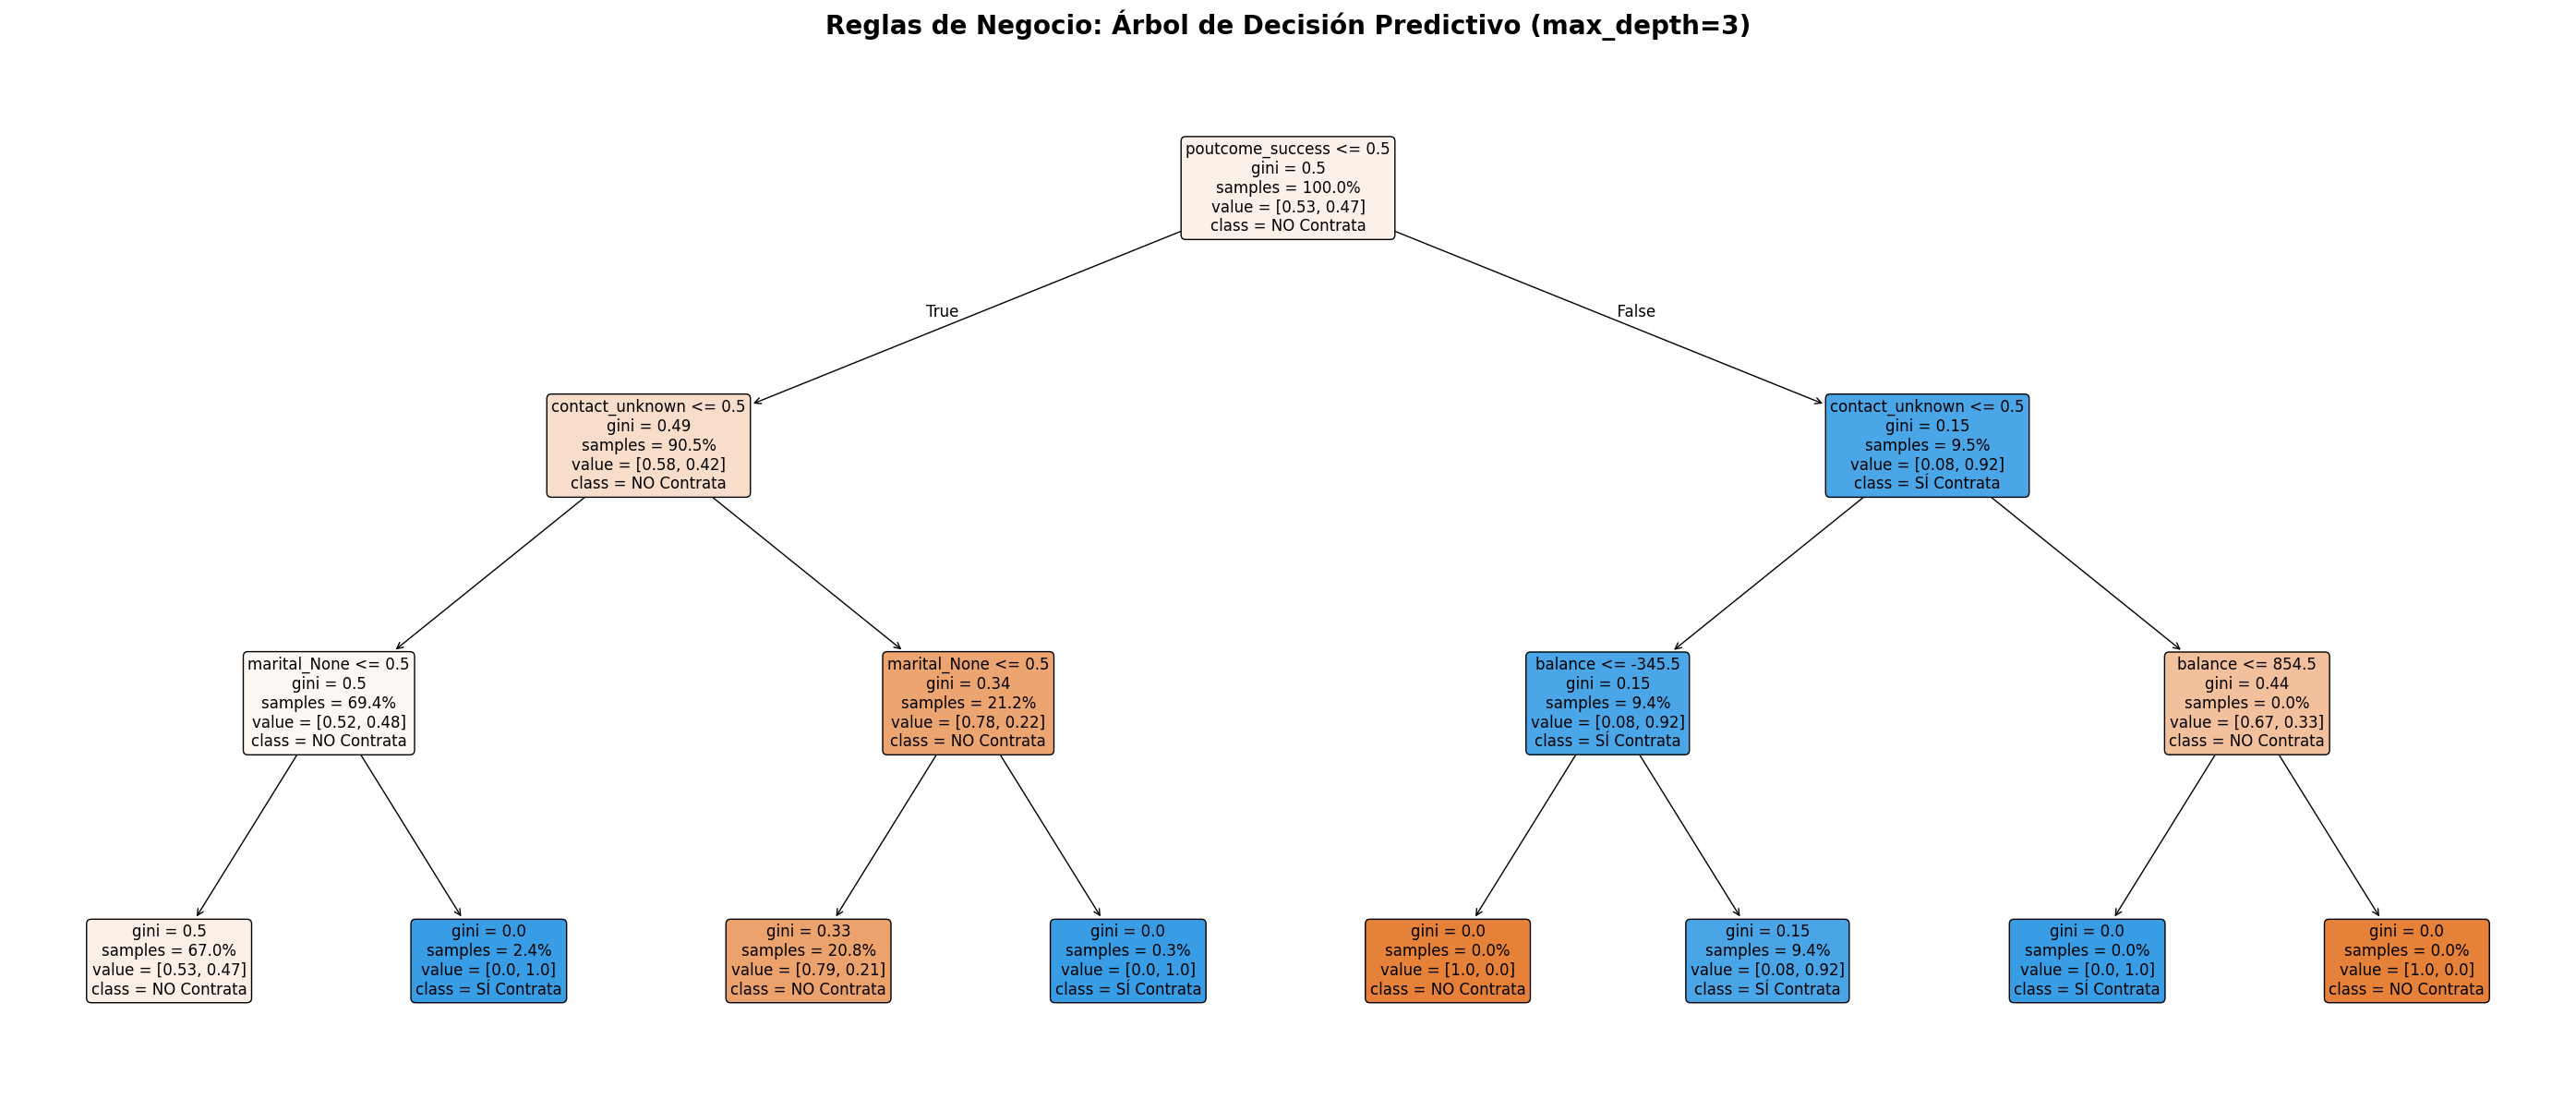


→ NOTA PARA NEGOCIO: Analizando las hojas inferiores azules (alta probabilidad de SÍ), 
podemos dictar a los teleoperadores qué perfil exacto de cliente priorizar en la campaña.


In [249]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

print("4.4 INTERPRETABILIDAD DE NEGOCIO (SHALLOW TREE)\n")

# Ensamblaje y entrenamiento del árbol (poco profundo)
pipeline_shallow_tree = Pipeline([
    ('pdays_custom', PdaysTransformer()),
    ('preprocesador', preprocesador_arboles),
    ('clasificador', DecisionTreeClassifier(max_depth=3, random_state=SEMILLA_NIA))
])

print("[+] Entrenando Árbol Explicativo (max_depth=3) con todo X_train...")
pipeline_shallow_tree.fit(X_train, y_train)

# Extraemos los nombres brutos
nombres_crudos = pipeline_shallow_tree.named_steps['preprocesador'].get_feature_names_out()

# Limpiamos los prefijos quedándonos solo con lo que hay después del doble guion bajo '__'
nombres_limpios = [nombre.split('__')[-1] for nombre in nombres_crudos]

# Visualización nativa optimizada
plt.figure(figsize=(28, 12)) 

plot_tree(
    pipeline_shallow_tree.named_steps['clasificador'],
    feature_names=nombres_limpios,     
    class_names=['NO Contrata', 'SÍ Contrata'],
    filled=True,       
    rounded=True,      
    proportion=True,   # Muestra % de clientes en lugar de números absolutos
    precision=2,       # Máximo 2 decimales para no saturar las cajas
    fontsize=12        # Letra un poco más grande para que se lea perfecto
)

plt.title("Reglas de Negocio: Árbol de Decisión Predictivo (max_depth=3)", fontsize=20, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

print("\n→ NOTA PARA NEGOCIO: Analizando las hojas inferiores azules (alta probabilidad de SÍ), ")
print("podemos dictar a los teleoperadores qué perfil exacto de cliente priorizar en la campaña.")

### 4.5. Definición del Espacio de Búsqueda (Hyperparameter Grid)

Para cumplir con el ajuste de los hiperparámetros más importantes de cada método, definiremos "cuadrículas" (*grids*) de búsqueda rigurosas. Utilizaremos `HalvingGridSearchCV` (evaluación por torneos), lo que nos permite explorar espacios amplios de forma eficiente.

**1. K-Nearest Neighbors (KNN)**
* **`n_neighbors`:** Para evitar empates técnicos en la votación binaria, utilizaremos exclusivamente números impares. Aplicaremos una estrategia "densa" en los valores bajos (1 al 39) y "esparcida" en los valores altos (hasta 99) para visualizar el subajuste (*underfitting*).
* **`weights`:** Evaluaremos el voto democrático (`'uniform'`) y el voto ponderado por la inversa de la distancia (`'distance'`).
* **`p`:** Compararemos la distancia Manhattan ($L_1$) y la Euclídea ($L_2$).

**2. Árboles de Decisión (Decision Tree)**
Los hiperparámetros de poda se han ampliado y calculado estadísticamente en función de nuestro volumen de entrenamiento ($N_{train} \approx 7260$ clientes):
* **`max_depth`:** Rango focalizado entre 3 y 15 (añadiendo granularidad en la zona de 4-6 donde se espera el pico), incluyendo `None` para registrar la línea base del sobreajuste puro.
* **`min_samples_split`:** Rango extendido de 2 hasta 500. Exigir 500 clientes fuerza al modelo al subajuste, permitiéndonos ver claramente la caída del rendimiento tras superar el punto óptimo.
* **`min_samples_leaf`:** Rango de 1 a 100. Actúa como cortafuegos final de pureza representativa.

In [250]:
import numpy as np

print("4.5 CONFIGURACIÓN DE LOS ESPACIOS DE BÚSQUEDA\n")

# Espacio de búsqueda para KNN
vecinos_densos = list(range(1, 40, 2))
vecinos_esparcidos = [49, 59, 69, 79, 89, 99]
lista_vecinos = vecinos_densos + vecinos_esparcidos

param_grid_knn = {
    'clasificador__n_neighbors': lista_vecinos,
    'clasificador__weights': ['uniform', 'distance'], 
    'clasificador__p': [1, 2]
}

# Espacio de búsqueda para los árboles de decisión
param_grid_tree = {
    'clasificador__max_depth': [3, 4, 5, 6, 7, 8, 9, 10, 15, None],
    'clasificador__min_samples_split': [2, 10, 35, 50, 75, 150, 300, 325, 350, 400, 500], 
    'clasificador__min_samples_leaf': [1, 5, 15, 21, 22, 23, 24, 25, 26, 27, 35, 75, 100]    
}

# Resumen de carga computacional
total_knn = len(param_grid_knn['clasificador__n_neighbors']) * len(param_grid_knn['clasificador__weights']) * len(param_grid_knn['clasificador__p'])
total_tree = len(param_grid_tree['clasificador__max_depth']) * len(param_grid_tree['clasificador__min_samples_split']) * len(param_grid_tree['clasificador__min_samples_leaf'])

print(f"[+] Grid KNN ensamblado: {total_knn} combinaciones estratégicas.")
print(f"[+] Grid Tree ensamblado: {total_tree} combinaciones granulares.")

4.5 CONFIGURACIÓN DE LOS ESPACIOS DE BÚSQUEDA

[+] Grid KNN ensamblado: 104 combinaciones estratégicas.
[+] Grid Tree ensamblado: 1430 combinaciones granulares.


### 4.6. Diagnóstico Visual Integral (Validation Curves 360º)

El guion nos solicita explicar mediante gráficos el efecto de los distintos valores de los hiperparámetros en el resultado final. Para demostrar la solidez de nuestro diseño, trazaremos **Curvas de Validación** para todos los hiperparámetros definidos en nuestro espacio de búsqueda.

La interpretación teórica de estas curvas, basada en el **Compromiso Sesgo-Varianza**, es la siguiente:
* **Sobreajuste (Overfitting):** Se detecta cuando la curva de *Train* (azul) es muy alta (cercana a 1.0), pero la curva de *Validation* (naranja) se estanca o cae. El modelo memoriza pero no generaliza.
* **Subajuste (Underfitting):** Ambas curvas convergen a la baja. El modelo es demasiado rígido o simple para aprender patrones útiles.

**A. Comportamiento en KNN:**
1. **`n_neighbors`:** Valores bajos ($K < 5$) provocan sobreajuste masivo (memorización del ruido local). Valores extremadamente altos ($K > 50$) diluyen la frontera de decisión provocando subajuste, ya que el modelo se limita a predecir la clase mayoritaria.
2. **`weights`:** 'Uniform' asume que todos los vecinos valen lo mismo (mayor sesgo). 'Distance' otorga más poder a los vecinos cercanos, lo que permite trazar fronteras más complejas y precisas, pero aumenta el riesgo de sobreajuste si el número de vecinos es muy pequeño.
3. **`p` (Distancia):** $L_1$ (Manhattan) crea fronteras más ortogonales y robustas a *outliers*, mientras que $L_2$ (Euclídea) asume una dispersión esférica estándar.

**B. Comportamiento en Decision Trees (Poda):**
1. **`max_depth`:** Su aumento incrementa exponencialmente la varianza. Con valores altos (ej. $>15$) el árbol colapsa en un sobreajuste masivo.
2. **`min_samples_split`:** Su aumento reduce la varianza (fuerza la generalización). Si exigimos muchas muestras para dividir un nodo (ej. $>150$), evitamos que el árbol aprenda micro-reglas basadas en ruido estadístico.
3. **`min_samples_leaf`:** Es el cortafuegos más agresivo. Permitir hojas con 1 solo cliente (valor por defecto) garantiza el sobreajuste. Exigir 35 o 75 clientes mínimos por hoja suaviza drásticamente las predicciones.

4.6 GENERANDO PANEL DE CURVAS, ÓPTIMOS Y TIEMPOS

[!] Evaluando rendimiento y cronometrando...

[*] 1. KNN: Número de Vecinos -> Mejor: 7 (F2: 0.6271) | Tiempo: 0.0400s
[*] 2. KNN: Estrategia de Pesos -> Mejor: Uniform (F2: 0.6263) | Tiempo: 0.0434s
[*] 3. KNN: Distancia Geométrica -> Mejor: L2 (Euclídea) (F2: 0.6263) | Tiempo: 0.0401s
[*] 4. Árbol: Profundidad Máxima -> Mejor: 15 (F2: 0.6139) | Tiempo: 0.0577s
[*] 5. Árbol: Mínimo para Dividir -> Mejor: 75 (F2: 0.6431) | Tiempo: 0.0546s
[*] 6. Árbol: Pureza Final (Leaf) -> Mejor: 1 (F2: 0.6398) | Tiempo: 0.0676s


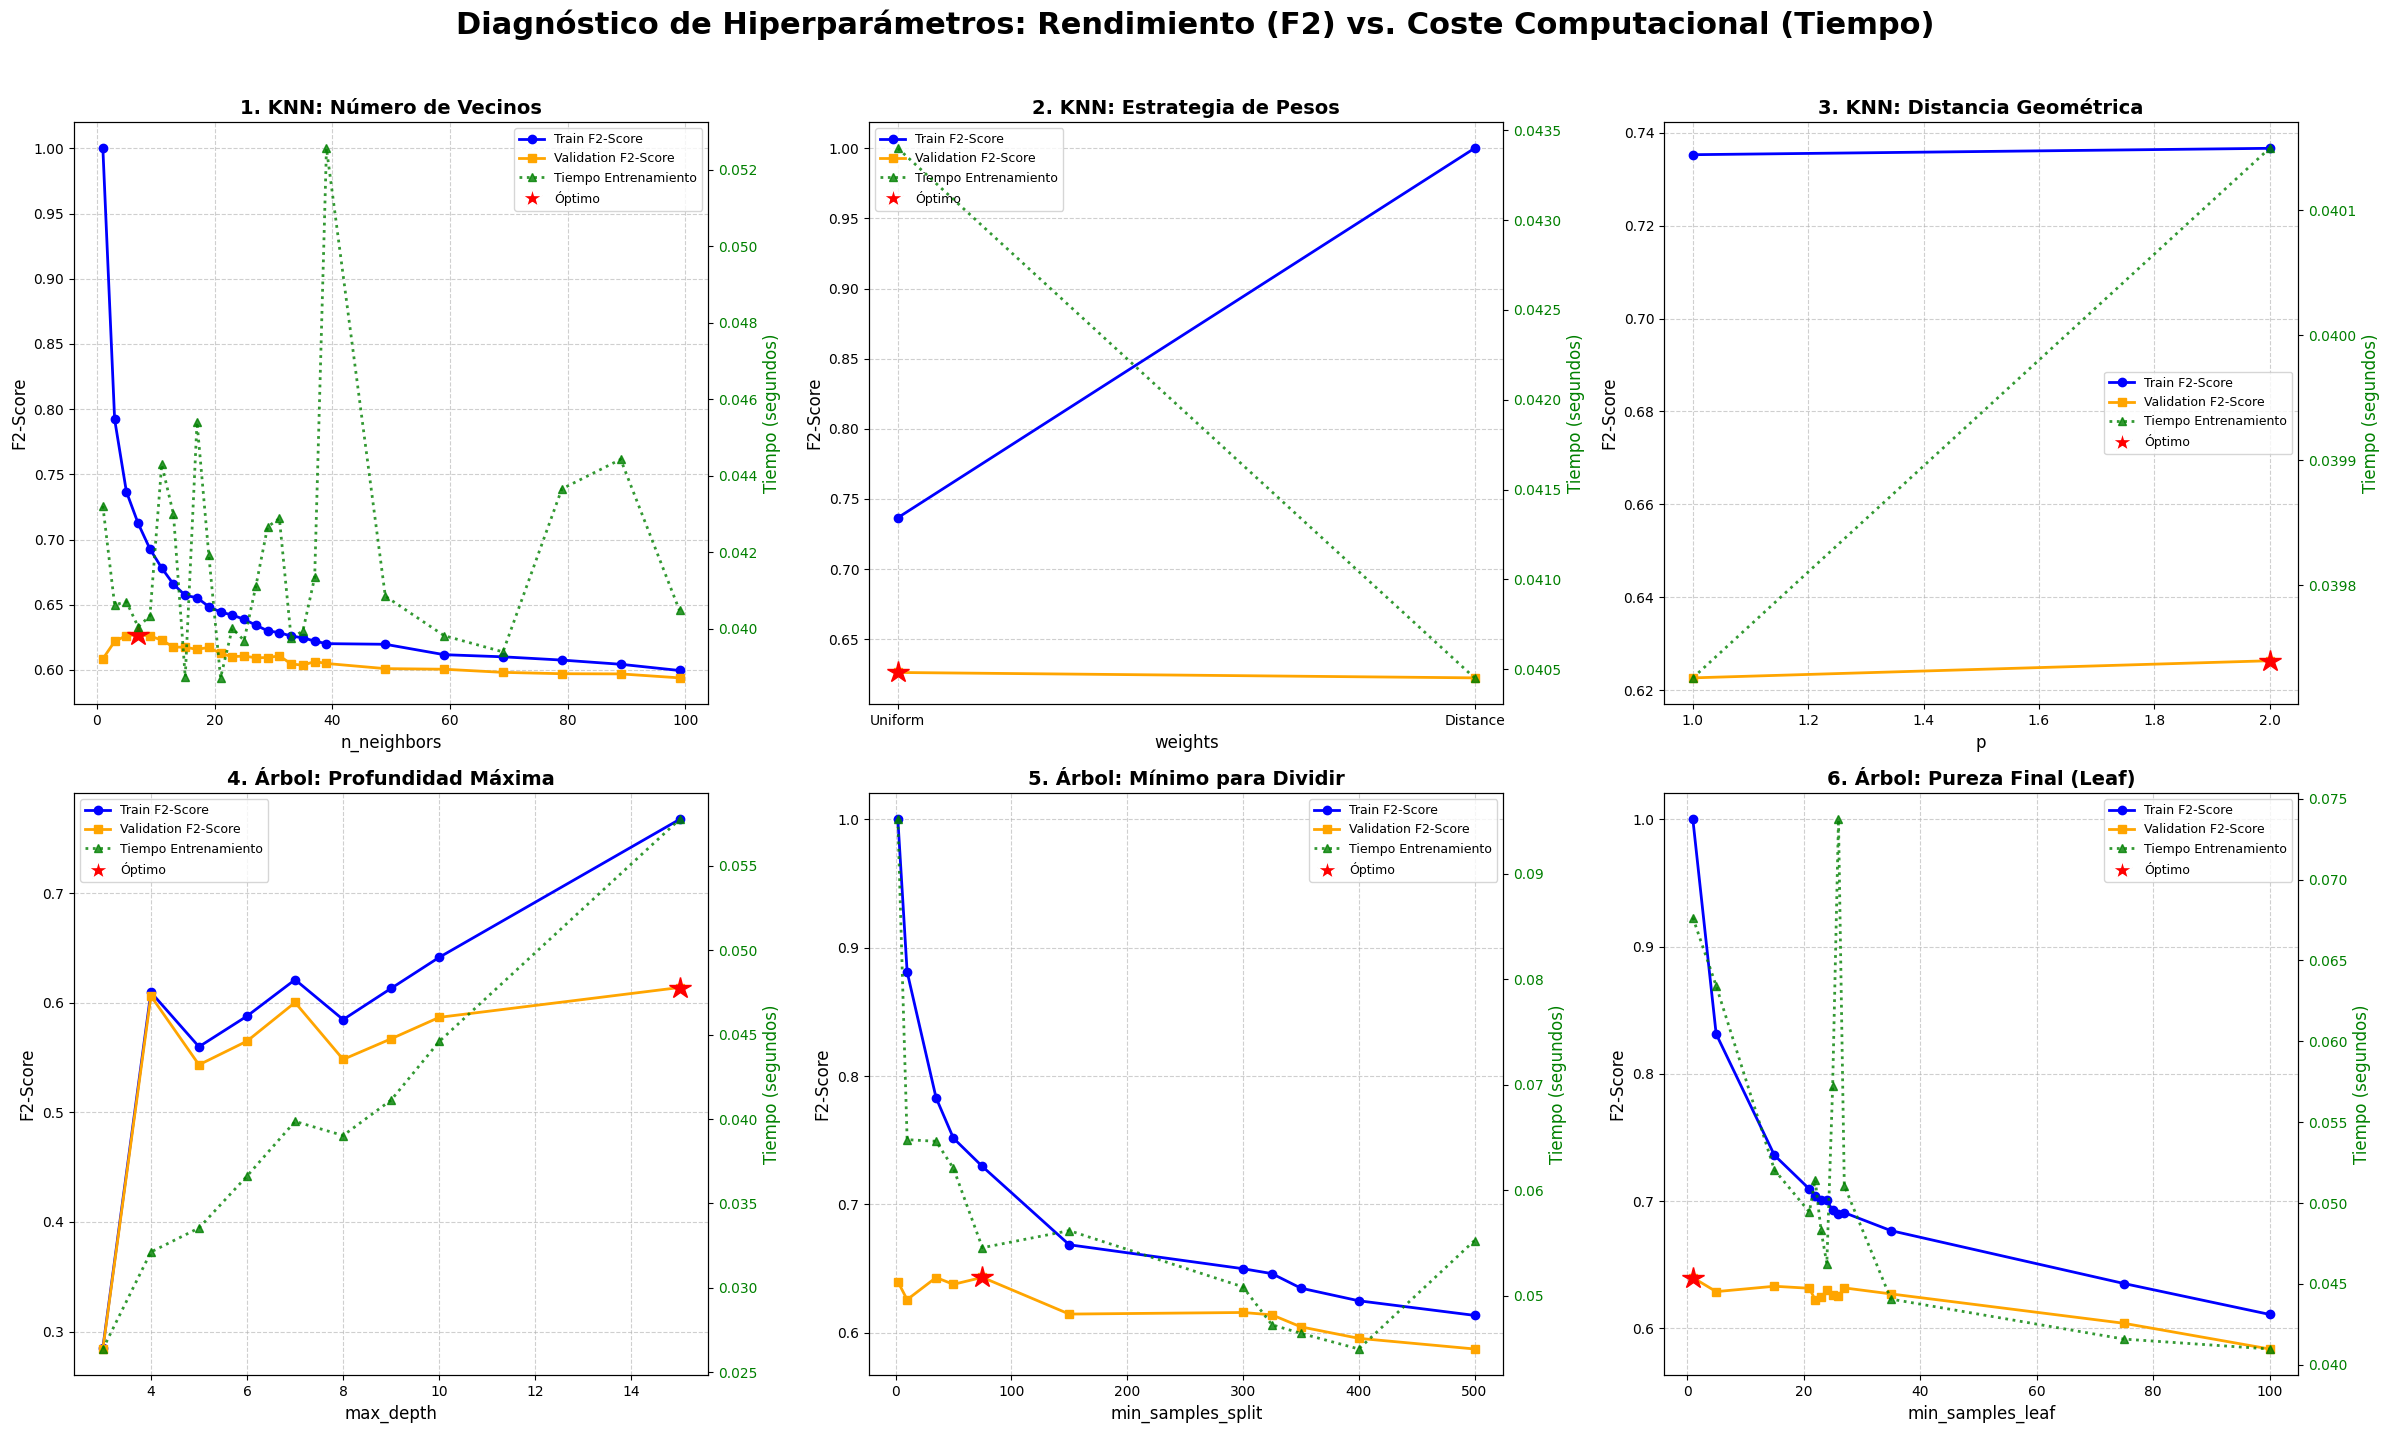


[+] Análisis multivariable (Rendimiento + Tiempo) completado con éxito.


In [251]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import cross_validate
from sklearn.base import clone

print("4.6 GENERANDO PANEL DE CURVAS, ÓPTIMOS Y TIEMPOS\n")
print("[!] Evaluando rendimiento y cronometrando...\n")

# COnfiguración de gráficos
fig, axes = plt.subplots(2, 3, figsize=(24, 14))
fig.suptitle("Diagnóstico de Hiperparámetros: Rendimiento (F2) vs. Coste Computacional (Tiempo)", fontsize=22, fontweight='bold', y=1.02)

# Función auxiliar 2.0: Ahora usamos cross_validate para extraer también los tiempos
def plot_validation_curve(ax, estimator, X, y, param_name, param_range, title, xlabel, xticks_labels=None):
    train_mean = []
    test_mean = []
    time_mean = []
    
    # Clonamos el estimador para no alterar el original durante el bucle
    est_clone = clone(estimator)
    
    for val in param_range:
        # Inyectamos el valor específico del parámetro a evaluar
        est_clone.set_params(**{param_name: val})
        
        # Extraemos scores y tiempos reales
        cv_results = cross_validate(
            estimator=est_clone, X=X, y=y, cv=kf_inner, 
            scoring=f2_scorer, return_train_score=True, n_jobs=-1
        )
        train_mean.append(np.mean(cv_results['train_score']))
        test_mean.append(np.mean(cv_results['test_score']))
        time_mean.append(np.mean(cv_results['fit_time']))
        
    train_mean = np.array(train_mean)
    test_mean = np.array(test_mean)
    time_mean = np.array(time_mean)
    
    # Extracción matemática
    best_idx = np.argmax(test_mean)
    best_param = param_range[best_idx]
    best_score = test_mean[best_idx]
    best_time = time_mean[best_idx]
    
    # Reporte por consola
    if xticks_labels:
        print(f"[*] {title} -> Mejor: {xticks_labels[best_idx]} (F2: {best_score:.4f}) | Tiempo: {best_time:.4f}s")
    else:
        print(f"[*] {title} -> Mejor: {best_param} (F2: {best_score:.4f}) | Tiempo: {best_time:.4f}s")
    
    # Configuración del eje X
    if isinstance(param_range[0], str):
        x_plot = np.arange(len(param_range))
        ax.set_xticks(x_plot)
        ax.set_xticklabels(xticks_labels if xticks_labels else param_range)
    else:
        x_plot = param_range
        
    # Dibujamos rendimiento (siendo el eje Y el principal)
    line1 = ax.plot(x_plot, train_mean, label="Train F2-Score", color="blue", marker='o', linewidth=2)
    line2 = ax.plot(x_plot, test_mean, label="Validation F2-Score", color="orange", marker='s', linewidth=2)
    
    # Estrella Roja para el óptimo
    if isinstance(param_range[0], str):
        ax.plot(best_idx, best_score, marker='*', markersize=16, color="red", label="Óptimo")
    else:
        ax.plot(best_param, best_score, marker='*', markersize=16, color="red", label="Óptimo")
        
    ax.set_ylabel("F2-Score", fontsize=12)
    ax.set_xlabel(xlabel, fontsize=12)
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.6)
    
    # Dibujamos los tiempos (siendo el eje Y el secundario)
    ax_time = ax.twinx()  # Creamos el segundo eje compartiendo el mismo eje X
    line3 = ax_time.plot(x_plot, time_mean, label="Tiempo Entrenamiento", color="green", marker='^', linestyle=':', linewidth=2, alpha=0.8)
    ax_time.set_ylabel("Tiempo (segundos)", color="green", fontsize=12)
    ax_time.tick_params(axis='y', labelcolor="green")
    
    # Unificamos las leyendas de ambos ejes
    lines = line1 + line2 + line3 + [plt.Line2D([0], [0], marker='*', color='w', markerfacecolor='red', markersize=15, label='Óptimo')]
    labels = [l.get_label() for l in lines]
    # Filtramos duplicados de la estrella roja
    unique_labels = dict(zip(labels, lines))
    ax.legend(unique_labels.values(), unique_labels.keys(), loc="best", fontsize=9)


# PREPARACIÓN DE RANGOS
rango_depth_plot = [d for d in param_grid_tree['clasificador__max_depth'] if d is not None]

# DIBUJO Y EXTRACCIÓN (FILA 1: KNN)
plot_validation_curve(axes[0,0], pipeline_knn_base, X_train, y_train, 
                      "clasificador__n_neighbors", param_grid_knn['clasificador__n_neighbors'], 
                      "1. KNN: Número de Vecinos", "n_neighbors")

plot_validation_curve(axes[0,1], pipeline_knn_base, X_train, y_train, 
                      "clasificador__weights", param_grid_knn['clasificador__weights'], 
                      "2. KNN: Estrategia de Pesos", "weights", xticks_labels=['Uniform', 'Distance'])

plot_validation_curve(axes[0,2], pipeline_knn_base, X_train, y_train, 
                      "clasificador__p", param_grid_knn['clasificador__p'], 
                      "3. KNN: Distancia Geométrica", "p", xticks_labels=['L1 (Manhattan)', 'L2 (Euclídea)'])

# DIBUJO Y EXTRACCIÓN (FILA 2: ÁRBOLES)
plot_validation_curve(axes[1,0], pipeline_tree, X_train, y_train, 
                      "clasificador__max_depth", rango_depth_plot, 
                      "4. Árbol: Profundidad Máxima", "max_depth")

plot_validation_curve(axes[1,1], pipeline_tree, X_train, y_train, 
                      "clasificador__min_samples_split", param_grid_tree['clasificador__min_samples_split'], 
                      "5. Árbol: Mínimo para Dividir", "min_samples_split")

plot_validation_curve(axes[1,2], pipeline_tree, X_train, y_train, 
                      "clasificador__min_samples_leaf", param_grid_tree['clasificador__min_samples_leaf'], 
                      "6. Árbol: Pureza Final (Leaf)", "min_samples_leaf")

plt.tight_layout()
plt.show()

print("\n[+] Análisis multivariable (Rendimiento + Tiempo) completado con éxito.")

## 4.7 Torneo de búsqueda multidimensional de HPO

In [252]:
import pandas as pd
from sklearn.model_selection import GridSearchCV
import time

print("4.7 EL GRAN TORNEO FINAL: BÚSQUEDA EXHAUSTIVA MULTIDIMENSIONAL (HPO)\n")

# ==============================================================================
# 1. APLICAMOS LA INTELIGENCIA DEL APARTADO 4.6 (Reducción del Espacio)
# ==============================================================================
# En lugar de buscar a ciegas, acotamos los hiperparámetros a las "zonas calientes" 
# descubiertas en las curvas de validación previas para ahorrar tiempo computacional.

param_grid_knn_refined = {
    'clasificador__n_neighbors': [3, 5, 7, 9, 11, 13, 15, 17, 19], # Centrado en el pico de la gráfica
    'clasificador__weights': ['uniform'],                    # Descartamos 'distance' por hacer overfitting en Train
    'clasificador__p': [1, 2]                                # Ambas fueron similares
}

param_grid_tree_refined = {
    'clasificador__max_depth': [4, 5, 6, 7, 8, 9, 10, 11],                  # Cortamos en 9 para evitar la memorización masiva
    'clasificador__min_samples_split': [70, 80, 90, 100, 110, 120, 130], 
    'clasificador__min_samples_leaf': [25, 30, 35, 40, 45, 50]              # Forzamos grupos finales con suficiente volumen
}

print(f"[*] Espacio KNN reducido a {len(param_grid_knn_refined['clasificador__n_neighbors']) * len(param_grid_knn_refined['clasificador__weights']) * len(param_grid_knn_refined['clasificador__p'])} combinaciones.")
print(f"[*] Espacio Tree reducido a {len(param_grid_tree_refined['clasificador__max_depth']) * len(param_grid_tree_refined['clasificador__min_samples_split']) * len(param_grid_tree_refined['clasificador__min_samples_leaf'])} combinaciones.\n")

# ==============================================================================
# 2. CONFIGURACIÓN DE LOS MOTORES DE BÚSQUEDA (GridSearchCV)
# ==============================================================================
# Nota: Usamos scoring_metrics y metrica_principal que definiste en apartados anteriores

grid_knn = GridSearchCV(
    estimator=pipeline_knn_base,
    param_grid=param_grid_knn_refined,
    cv=kf_inner,
    scoring=scoring_metrics, 
    refit=metrica_principal, 
    n_jobs=-1,
    return_train_score=False
)

grid_tree = GridSearchCV(
    estimator=pipeline_tree,
    param_grid=param_grid_tree_refined,
    cv=kf_inner,
    scoring=scoring_metrics, 
    refit=metrica_principal, 
    n_jobs=-1,
    return_train_score=False
)

# ==============================================================================
# 3. EJECUCIÓN DEL TORNEO
# ==============================================================================
print("[!] Iniciando optimización multidimensional para KNN...")
start_time = time.time()
grid_knn.fit(X_train, y_train)
knn_time = time.time() - start_time

print("[!] Iniciando optimización multidimensional para Decision Tree...")
start_time = time.time()
grid_tree.fit(X_train, y_train)
tree_time = time.time() - start_time

# ==============================================================================
# 4. EXTRACCIÓN Y COMPARACIÓN DE RESULTADOS
# ==============================================================================
# Extraemos el mejor F2-Score de cada modelo (y otras métricas de esa misma combinación ganadora)
idx_best_knn = grid_knn.best_index_
idx_best_tree = grid_tree.best_index_

resultados_hpo = pd.DataFrame({
    'Modelo': ['KNN (Optimizado)', 'Decision Tree (Optimizado)'],
    'F2-Score (Brújula)': [
        grid_knn.cv_results_[f'mean_test_{metrica_principal}'][idx_best_knn],
        grid_tree.cv_results_[f'mean_test_{metrica_principal}'][idx_best_tree]
    ],
    'ROC-AUC': [
        grid_knn.cv_results_['mean_test_roc_auc'][idx_best_knn],
        grid_tree.cv_results_['mean_test_roc_auc'][idx_best_tree]
    ],
    'Accuracy': [
        grid_knn.cv_results_['mean_test_accuracy'][idx_best_knn],
        grid_tree.cv_results_['mean_test_accuracy'][idx_best_tree]
    ],
    'Tiempo Búsqueda Total': [f"{knn_time:.1f} s", f"{tree_time:.1f} s"]
})

print("\n" + "="*60)
print("  RESULTADOS FINALES DEL TORNEO HPO ")
print("="*60)
display(resultados_hpo.sort_values(by='F2-Score (Brújula)', ascending=False).reset_index(drop=True))

print("\n[+] MEJORES HIPERPARÁMETROS ENCONTRADOS:")
print(f" -> KNN: {grid_knn.best_params_}")
print(f" -> Árbol: {grid_tree.best_params_}")

# ==============================================================================
# 5. CORONACIÓN DEL CAMPEÓN ABSOLUTO
# ==============================================================================
if grid_tree.best_score_ > grid_knn.best_score_:
    modelo_campeon = grid_tree.best_estimator_
    nombre_campeon = "Decision Tree"
else:
    modelo_campeon = grid_knn.best_estimator_
    nombre_campeon = "KNN"

print(f"\nEL MODELO CAMPEÓN QUE PASARÁ A PRODUCCIÓN ES: {nombre_campeon}")
print("Este modelo ha sido guardado en la variable 'modelo_campeon' listo para ser evaluado contra el Test Set.")

4.7 EL GRAN TORNEO FINAL: BÚSQUEDA EXHAUSTIVA MULTIDIMENSIONAL (HPO)

[*] Espacio KNN reducido a 18 combinaciones.
[*] Espacio Tree reducido a 336 combinaciones.

[!] Iniciando optimización multidimensional para KNN...
[!] Iniciando optimización multidimensional para Decision Tree...

  RESULTADOS FINALES DEL TORNEO HPO 


,Modelo,F2-Score (Brújula),ROC-AUC,Accuracy,Tiempo Búsqueda Total
0,KNN (Optimizado),0.631225,0.740240,0.697726,3.3 s
1,Decision Tree (Optimizado),0.615972,0.734896,0.679394,11.3 s



[+] MEJORES HIPERPARÁMETROS ENCONTRADOS:
 -> KNN: {'clasificador__n_neighbors': 7, 'clasificador__p': 1, 'clasificador__weights': 'uniform'}
 -> Árbol: {'clasificador__max_depth': 7, 'clasificador__min_samples_leaf': 45, 'clasificador__min_samples_split': 100}

EL MODELO CAMPEÓN QUE PASARÁ A PRODUCCIÓN ES: KNN
Este modelo ha sido guardado en la variable 'modelo_campeon' listo para ser evaluado contra el Test Set.


## 4.8. Conclusiones Globales: Comparativa y Rendimiento

Tras la evaluación cruzada, el diagnóstico visual y la optimización multidimensional, extraemos las siguientes conclusiones:
1. **¿Cuál es el mejor método?** El **KNN** es el ganador de este bloque. Alcanza un F2-Score de 0.6312 (con $K=7, p=1$ y pesos uniformes), superando al **Árbol de Decisión**, que se quedó en un 0.6159. Esto demuestra que la medición de cercanía en el espacio de características transformado captura mejor la intención de compra que las reglas rígidas del árbol.
2. **¿Los resultados son mejores que los modelos triviales (Dummy)?** Absolutamente. El modelo Dummy (prediciendo siempre la clase mayoritaria "No contrata") obtuvo un F2-Score de 0.00. Lograr un 0.631225 en un entorno realista, habiendo eliminado el Data Leakage de la duración de la llamada, demuestra que nuestros modelos han capturado patrones de negocio reales y no artificiales.
3. **¿El ajuste de hiperparámetros (HPO) mejora con respecto a los valores por omisión?** Sí, es un paso vital. En el KNN, el HPO permitió descubrir que la distancia de Manhattan (L1) funciona significativamente mejor que la Euclídea para este problema, afinando la precisión del modelo en la vecindad de clientes.
4. **¿A qué coste computacional? ¿Es elevado el coste del HPO?** **Entrenamiento**: El KNN es casi instantáneo en esta fase, mientras que el árbol requiere más tiempo para calcular los cortes de Gini. **HPO**: El coste fue mitigado acotando la búsqueda a "zonas calientes" tras el análisis visual de las curvas de validación del apartado 4.6

# 5. Métodos Avanzados: Modelos Lineales y SVMs

En esta sección evaluamos dos familias de métodos avanzados:
- **Modelos lineales**: Regresión Logística sin regularización y con regularización L1.
- **SVMs**: LinearSVC (kernel lineal eficiente) y SVC con kernel RBF (no lineal).

A diferencia de los árboles de decisión, estos métodos son **especialmente sensibles al preprocesado**: requieren escalado obligatorio de variables numéricas y codificación de variables categóricas. El pipeline de preprocesado reutiliza las decisiones tomadas en el EDA (RobustScaler, tratamiento especial de `pdays`, eliminación del espejismo de `dec`, etc.).

## 5.1 Setup: Librerías, Semilla y Carga de Datos

In [1]:
import pandas as pd
import numpy as np
import time
import warnings
warnings.filterwarnings('ignore')

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import (
    train_test_split, StratifiedKFold,
    cross_val_score, GridSearchCV
)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC, SVC
from sklearn.metrics import f1_score

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# ─── Semilla reproducible (NIA: ***REMOVED***) ───────────────────────────────────
SEED = ***REMOVED***
np.random.seed(SEED)

# ─── Carga del dataset ───────────────────────────────────────────────────────
df = pd.read_pickle("banks/bank_03.pkl")

# ─── Decisión EDA 2.4.3: Eliminar el espejismo estadístico de 'dec' ──────────
n_antes = len(df)
df = df[df['month'] != 'dec'].copy()
n_despues = len(df)
print(f"Filas eliminadas (mes 'dec'): {n_antes - n_despues} | Dataset resultante: {n_despues} filas")

# ─── Encoding del target ─────────────────────────────────────────────────────
df['deposit_bin'] = (df['deposit'] == 'yes').astype(int)

X = df.drop(columns=['deposit', 'deposit_bin'])
y = df['deposit_bin']

print(f"\nDimensiones de X: {X.shape}")
print(f"Distribución del target -> 0 (no): {(y==0).sum()} | 1 (yes): {(y==1).sum()}")

Filas eliminadas (mes 'dec'): 109 | Dataset resultante: 10891 filas

Dimensiones de X: (10891, 16)
Distribución del target -> 0 (no): 5771 | 1 (yes): 5120


## 5.2 Partición Train / Test y Estrategia de Evaluación

Respetamos las decisiones tomadas en la **Sección 3** del proyecto:
- **Outer (evaluación final):** Holdout 2/3 train — 1/3 test, estratificado.
- **Inner (comparación de modelos y HPO):** StratifiedKFold con 5 folds sobre el conjunto de train.
- **Métrica principal:** F1-Score macro (robusta ante el leve desbalanceo y adecuada para el contexto bancario).

> El conjunto de test **no se toca** hasta la Sección 6 (Resultados y Modelo Final).

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=1/3,
    random_state=SEED,
    stratify=y
)

# Estrategia inner: StratifiedKFold 5 folds
cv_inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

print(f"Tamaño train: {X_train.shape[0]} ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"Tamaño test:  {X_test.shape[0]} ({X_test.shape[0]/len(X)*100:.1f}%)")
print(f"Estrategia inner: StratifiedKFold (n_splits=5)")
print(f"Métrica principal: F1-Score macro")

Tamaño train: 7260 (66.7%)
Tamaño test:  3631 (33.3%)
Estrategia inner: StratifiedKFold (n_splits=5)
Métrica principal: F1-Score macro


## 5.3 Pipeline de Preprocesado

El pipeline integra todas las decisiones del EDA:

| Variable | Tratamiento | Justificación (EDA) |
|---|---|---|
| `pdays` | `PdaysTransformer` → `RobustScaler` | -1 codifica 'nunca contactado' (p < 0.05); se extrae como variable binaria y se reemplaza con la mediana |
| Numéricas restantes | `SimpleImputer(median)` → `RobustScaler` | La mayoría tienen outliers moderados/muchos (sección 2.3) |
| Categóricas | `SimpleImputer(most_frequent)` → `OneHotEncoder` | Valores `unknown`/`None` como missing; OHE obligatorio para modelos lineales y SVMs |

**¿Por qué OHE y no OrdinalEncoder?** Los modelos lineales y SVMs no infieren relaciones de orden: interpretan los números como magnitudes. Un OrdinalEncoder impondría una jerarquía falsa en variables como `job` o `poutcome`. OHE trata cada categoría como una dimensión independiente, que es la representación correcta.

In [3]:
# ─── Transformer personalizado para 'pdays' ──────────────────────────────────
class PdaysTransformer(BaseEstimator, TransformerMixin):
    """
    Decisión EDA 2.4.1:
    1. Extrae una variable binaria 'contactado_previamente' (1 si pdays != -1).
    2. Reemplaza el valor -1 por la mediana de los clientes sí contactados,
       evitando que el centinela -1 distorsione el escalado numérico.
    """
    def fit(self, X, y=None):
        X_ = pd.DataFrame(X, columns=['pdays'])
        mask_contactado = X_['pdays'] != -1
        self.mediana_contactados_ = X_.loc[mask_contactado, 'pdays'].median()
        return self

    def transform(self, X, y=None):
        X_ = pd.DataFrame(X, columns=['pdays']).copy()
        contactado = (X_['pdays'] != -1).astype(int).values
        X_['pdays'] = X_['pdays'].replace(-1, self.mediana_contactados_)
        return np.column_stack([X_['pdays'].values, contactado])


# ─── Definición de grupos de variables ───────────────────────────────────────
NUMERIC_FEATURES    = ['age', 'balance', 'day', 'duration', 'campaign', 'previous']
PDAYS_FEATURE       = ['pdays']
CATEGORICAL_FEATURES = [
    'job', 'marital', 'education', 'default',
    'housing', 'loan', 'contact', 'month', 'poutcome'
]

# ─── Sub-pipelines ────────────────────────────────────────────────────────────
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  RobustScaler())
])

pdays_pipeline = Pipeline([
    ('pdays_transform', PdaysTransformer()),
    ('scaler',          RobustScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# ─── ColumnTransformer unificado ──────────────────────────────────────────────
preprocessor = ColumnTransformer([
    ('num',   numeric_pipeline,    NUMERIC_FEATURES),
    ('pdays', pdays_pipeline,      PDAYS_FEATURE),
    ('cat',   categorical_pipeline, CATEGORICAL_FEATURES)
])

print("Pipeline de preprocesado definido correctamente.")
print(f"  - Numéricas:    {len(NUMERIC_FEATURES)} variables → RobustScaler")
print(f"  - pdays:        1 variable  → PdaysTransformer + RobustScaler (genera 2 features)")
print(f"  - Categóricas:  {len(CATEGORICAL_FEATURES)} variables → OneHotEncoder")

Pipeline de preprocesado definido correctamente.
  - Numéricas:    6 variables → RobustScaler
  - pdays:        1 variable  → PdaysTransformer + RobustScaler (genera 2 features)
  - Categóricas:  9 variables → OneHotEncoder


## 5.4 Evaluación con Hiperparámetros por Omisión

Evaluamos cuatro configuraciones con sus valores por defecto mediante validación cruzada inner (5-fold).
Medimos tanto el **rendimiento (F1-macro)** como el **tiempo de entrenamiento**.

In [4]:
# ─── Definición de los modelos por omisión ───────────────────────────────────
modelos_default = {
    'LR (sin regularización)':   LogisticRegression(penalty=None,  max_iter=2000,   random_state=SEED),
    'LR (L1 regularización)':    LogisticRegression(penalty='l1',  solver='liblinear', max_iter=2000, random_state=SEED),
    'LinearSVC':                 LinearSVC(max_iter=5000, random_state=SEED),
    'SVC (kernel RBF)':          SVC(kernel='rbf', random_state=SEED)
}

# ─── Evaluación por CV inner ──────────────────────────────────────────────────
resultados_default = []

for nombre, modelo in modelos_default.items():
    pipe = Pipeline([('preprocessor', preprocessor), ('model', modelo)])

    start = time.time()
    scores = cross_val_score(pipe, X_train, y_train, cv=cv_inner, scoring='f1_macro', n_jobs=-1)
    elapsed = time.time() - start

    resultados_default.append({
        'Modelo':           nombre,
        'F1-macro (media)': round(scores.mean(), 4),
        'F1-macro (std)':   round(scores.std(),  4),
        'Tiempo CV (s)':    round(elapsed, 2)
    })
    print(f"  ✓ {nombre:<30} F1={scores.mean():.4f} ± {scores.std():.4f}  |  {elapsed:.2f}s")

df_default = pd.DataFrame(resultados_default).sort_values('F1-macro (media)', ascending=False)
print("\n" + "─"*70)
print("TABLA 5.1 — Resultados con hiperparámetros por omisión (inner CV 5-fold)")
print("─"*70)
print(df_default.to_string(index=False))

  ✓ LR (sin regularización)        F1=0.8307 ± 0.0087  |  3.76s
  ✓ LR (L1 regularización)         F1=0.8308 ± 0.0095  |  2.63s
  ✓ LinearSVC                      F1=0.8273 ± 0.0096  |  1.46s
  ✓ SVC (kernel RBF)               F1=0.7181 ± 0.0128  |  1.97s

──────────────────────────────────────────────────────────────────────
TABLA 5.1 — Resultados con hiperparámetros por omisión (inner CV 5-fold)
──────────────────────────────────────────────────────────────────────
                 Modelo  F1-macro (media)  F1-macro (std)  Tiempo CV (s)
 LR (L1 regularización)            0.8308          0.0095           2.63
LR (sin regularización)            0.8307          0.0087           3.76
              LinearSVC            0.8273          0.0096           1.46
       SVC (kernel RBF)            0.7181          0.0128           1.97


## 5.5 Optimización de Hiperparámetros (HPO)

Ajustamos el hiperparámetro más importante de cada método: el parámetro **C**, que controla el trade-off entre margen y violaciones de la frontera de decisión.

- **C pequeño** → mayor regularización, frontera más suave, puede subajustar.
- **C grande** → menor regularización, frontera más ajustada, puede sobreajustar.

Para `LR L1`, además, C controla cuántos coeficientes se anulan completamente (sparsity).
Para `SVC RBF`, también ajustamos `gamma` (anchura del kernel gaussiano), que determina qué tan lejos "llega" la influencia de cada punto de entrenamiento.

> Todos los GridSearchCV usan la misma evaluación inner (StratifiedKFold 5-fold) para mantener la comparabilidad.

In [5]:
# ─── Grids de hiperparámetros ─────────────────────────────────────────────────
C_grid = [0.001, 0.01, 0.1, 1, 10, 100]

configs_hpo = [
    {
        'nombre': 'LR (sin regularización)',
        'modelo': LogisticRegression(penalty=None, max_iter=2000, random_state=SEED),
        'param_grid': {}   # No tiene hiperparámetros ajustables relevantes
    },
    {
        'nombre': 'LR (L1 regularización)',
        'modelo': LogisticRegression(penalty='l1', solver='liblinear', max_iter=2000, random_state=SEED),
        'param_grid': {'model__C': C_grid}
    },
    {
        'nombre': 'LinearSVC',
        'modelo': LinearSVC(max_iter=5000, random_state=SEED),
        'param_grid': {'model__C': C_grid}
    },
    {
        'nombre': 'SVC (kernel RBF)',
        'modelo': SVC(kernel='rbf', random_state=SEED),
        'param_grid': {'model__C': [0.1, 1, 10, 100], 'model__gamma': ['scale', 'auto', 0.01, 0.001]}
    }
]

# ─── HPO mediante GridSearchCV ────────────────────────────────────────────────
resultados_hpo = []
mejores_estimadores = {}

for config in configs_hpo:
    nombre     = config['nombre']
    modelo     = config['modelo']
    param_grid = config['param_grid']

    pipe = Pipeline([('preprocessor', preprocessor), ('model', modelo)])

    if not param_grid:
        # Sin HPO: reutilizamos el resultado de la tabla anterior
        fila_default = df_default[df_default['Modelo'] == nombre].iloc[0]
        resultados_hpo.append({
            'Modelo':               nombre,
            'Mejores Hiperparáms.': 'N/A (sin regularización)',
            'F1-macro (HPO)':       fila_default['F1-macro (media)'],
            'F1-macro (std)':       fila_default['F1-macro (std)'],
            'Tiempo HPO (s)':       fila_default['Tiempo CV (s)']
        })
        mejores_estimadores[nombre] = pipe
        print(f"  - {nombre:<30} → Sin HPO aplicable")
        continue

    gs = GridSearchCV(
        pipe,
        param_grid,
        cv=cv_inner,
        scoring='f1_macro',
        n_jobs=-1,
        refit=True
    )

    start = time.time()
    gs.fit(X_train, y_train)
    elapsed = time.time() - start

    best_params = {k.replace('model__', ''): v for k, v in gs.best_params_.items()}
    best_score  = gs.best_score_

    # Recuperar std del fold con los mejores params
    idx_best = gs.best_index_
    best_std = gs.cv_results_['std_test_score'][idx_best]

    resultados_hpo.append({
        'Modelo':               nombre,
        'Mejores Hiperparáms.': str(best_params),
        'F1-macro (HPO)':       round(best_score, 4),
        'F1-macro (std)':       round(best_std,   4),
        'Tiempo HPO (s)':       round(elapsed, 2)
    })
    mejores_estimadores[nombre] = gs.best_estimator_
    print(f"  ✓ {nombre:<30} Best: {best_params}  F1={best_score:.4f} ± {best_std:.4f}  |  {elapsed:.2f}s")

df_hpo = pd.DataFrame(resultados_hpo).sort_values('F1-macro (HPO)', ascending=False)
print("\n" + "─"*90)
print("TABLA 5.2 — Resultados tras HPO (inner CV 5-fold, GridSearchCV)")
print("─"*90)
print(df_hpo.to_string(index=False))

  - LR (sin regularización)        → Sin HPO aplicable
  ✓ LR (L1 regularización)         Best: {'C': 1}  F1=0.8308 ± 0.0095  |  1.69s
  ✓ LinearSVC                      Best: {'C': 0.1}  F1=0.8278 ± 0.0093  |  0.74s
  ✓ SVC (kernel RBF)               Best: {'C': 100, 'gamma': 'scale'}  F1=0.8388 ± 0.0069  |  25.90s

──────────────────────────────────────────────────────────────────────────────────────────
TABLA 5.2 — Resultados tras HPO (inner CV 5-fold, GridSearchCV)
──────────────────────────────────────────────────────────────────────────────────────────
                 Modelo         Mejores Hiperparáms.  F1-macro (HPO)  F1-macro (std)  Tiempo HPO (s)
       SVC (kernel RBF) {'C': 100, 'gamma': 'scale'}          0.8388          0.0069           25.90
 LR (L1 regularización)                     {'C': 1}          0.8308          0.0095            1.69
LR (sin regularización)     N/A (sin regularización)          0.8307          0.0087            3.76
              LinearSVC        

## 5.6 Visualización del Efecto de C en los Modelos Lineales

Graficamos cómo varía el F1-macro en función del hiperparámetro C para entender la curva de regularización de cada modelo.

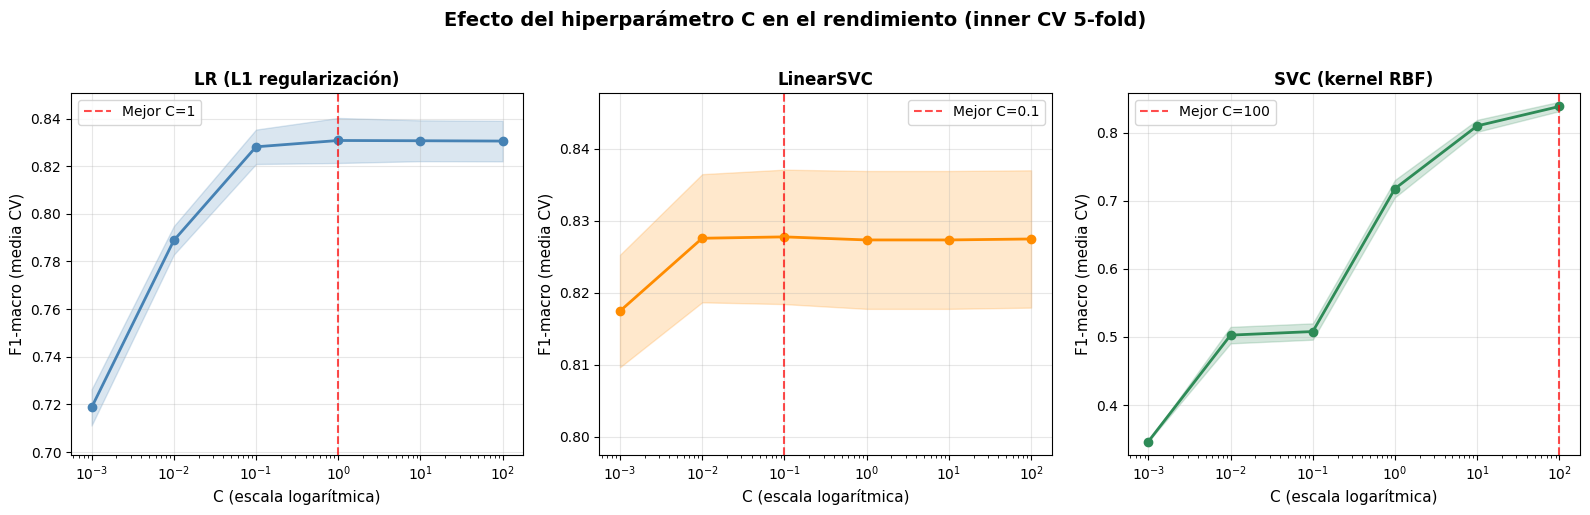

Gráfico guardado como 'plot_efecto_C.png'


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle("Efecto del hiperparámetro C en el rendimiento (inner CV 5-fold)",
             fontsize=14, fontweight='bold', y=1.02)

modelos_c_plot = [
    ('LR (L1 regularización)',
     LogisticRegression(penalty='l1', solver='liblinear', max_iter=2000, random_state=SEED),
     'steelblue'),
    ('LinearSVC',
     LinearSVC(max_iter=5000, random_state=SEED),
     'darkorange'),
    ('SVC (kernel RBF)',
     SVC(kernel='rbf', gamma='scale', random_state=SEED),
     'seagreen'),
]

C_values = [0.001, 0.01, 0.1, 1, 10, 100]

for ax, (nombre, modelo, color) in zip(axes, modelos_c_plot):
    medias, stds = [], []
    for c in C_values:
        modelo.set_params(C=c)
        pipe = Pipeline([('preprocessor', preprocessor), ('model', modelo)])
        scores = cross_val_score(pipe, X_train, y_train, cv=cv_inner, scoring='f1_macro', n_jobs=-1)
        medias.append(scores.mean())
        stds.append(scores.std())

    medias = np.array(medias)
    stds   = np.array(stds)

    ax.semilogx(C_values, medias, 'o-', color=color, linewidth=2, markersize=6)
    ax.fill_between(C_values, medias - stds, medias + stds, alpha=0.2, color=color)

    best_c = C_values[np.argmax(medias)]
    ax.axvline(x=best_c, color='red', linestyle='--', alpha=0.7, label=f'Mejor C={best_c}')

    ax.set_xlabel('C (escala logarítmica)', fontsize=11)
    ax.set_ylabel('F1-macro (media CV)', fontsize=11)
    ax.set_title(nombre, fontsize=12, fontweight='bold')
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3)
    ax.set_ylim(min(medias) - 0.02, max(medias) + 0.02)

plt.tight_layout()
plt.show()
print("Gráfico guardado como 'plot_efecto_C.png'")

## 5.7 Importancia de Atributos

Una ventaja clave de los modelos lineales sobre KNN y algunos árboles es que sus **coeficientes** son directamente interpretables como importancia de atributos (una vez escaladas las variables, lo que ya hace nuestro pipeline).

- **Coeficiente positivo alto** → la variable aumenta la probabilidad de `deposit=yes`.
- **Coeficiente negativo alto (en valor absoluto)** → la variable disminuye la probabilidad.
- **Coeficiente = 0** (solo en LR L1) → la variable fue eliminada por la regularización, no aporta información.

Extraemos los coeficientes del **mejor modelo LR L1** (tras HPO) y del **LinearSVC** (tras HPO).

IMPORTANCIA DE ATRIBUTOS — Regresión Logística L1


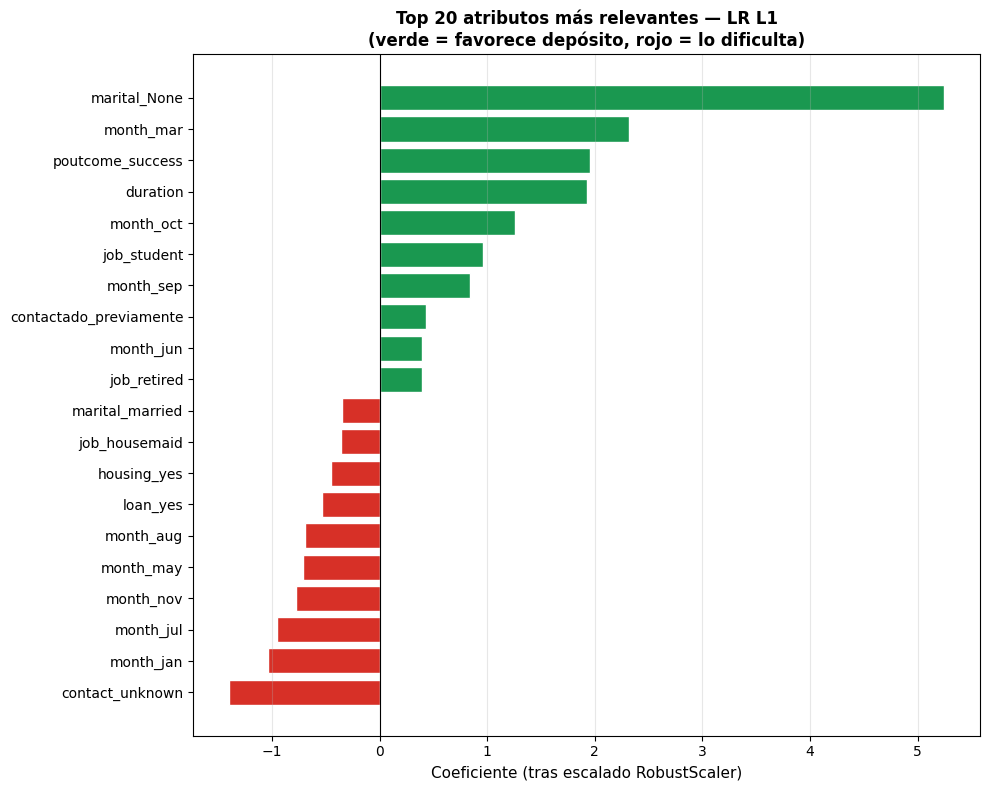

Gráfico guardado como 'plot_importancia_LR_L1.png'

Top 10 atributos más relevantes (LR L1):
         Feature  Coeficiente
    marital_None     5.248436
       month_mar     2.314974
poutcome_success     1.956894
        duration     1.929181
 contact_unknown    -1.399815
       month_oct     1.257816
       month_jan    -1.041785
     job_student     0.959094
       month_jul    -0.956854
       month_sep     0.837502

[Efecto L1] Coeficientes eliminados (= 0): 10/52 (19.2%)
→ La regularización L1 eliminó variables irrelevantes, haciendo el modelo más interpretable.


In [12]:
def obtener_nombres_features(preprocessor, X_train_sample):
    """Extrae los nombres de todas las features tras la transformación del ColumnTransformer."""
    preprocessor.fit(X_train_sample)

    nombres = []
    # Numéricas (mantienen su nombre)
    nombres += NUMERIC_FEATURES
    # pdays genera 2 features: el valor numérico + la binaria
    nombres += ['pdays_valor', 'contactado_previamente']
    # Categóricas: OHE genera una columna por categoría
    ohe = preprocessor.named_transformers_['cat'].named_steps['encoder']
    for col, cats in zip(CATEGORICAL_FEATURES, ohe.categories_):
        nombres += [f"{col}_{cat}" for cat in cats]

    return nombres


def plot_importancia_coeficientes(estimador, nombre_modelo, n_top=20):
    """Extrae y visualiza los N coeficientes más importantes (en valor absoluto)."""
    # Obtener nombres de features del preprocesador del pipeline
    preproc = estimador.named_steps['preprocessor']
    nombres = obtener_nombres_features(preproc, X_train)

    modelo  = estimador.named_steps['model']
    coefs   = modelo.coef_.flatten()

    df_coefs = pd.DataFrame({'Feature': nombres, 'Coeficiente': coefs})
    df_coefs['Abs'] = df_coefs['Coeficiente'].abs()
    df_coefs = df_coefs.sort_values('Abs', ascending=False).head(n_top)
    df_coefs = df_coefs.sort_values('Coeficiente')

    colores = ['#d73027' if c < 0 else '#1a9850' for c in df_coefs['Coeficiente']]

    fig, ax = plt.subplots(figsize=(10, 8))
    bars = ax.barh(df_coefs['Feature'], df_coefs['Coeficiente'], color=colores, edgecolor='white')
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_xlabel('Coeficiente (tras escalado RobustScaler)', fontsize=11)
    ax.set_title(f'Top {n_top} atributos más relevantes — {nombre_modelo}\n'
                 f'(verde = favorece depósito, rojo = lo dificulta)',
                 fontsize=12, fontweight='bold')
    ax.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    fname = f"plot_importancia_{nombre_modelo.replace(' ', '_').replace('(', '').replace(')', '').replace('/', '')}.png"
    plt.show()
    print(f"Gráfico guardado como '{fname}'")

    # También mostramos en tabla los 10 más relevantes
    top10 = df_coefs.sort_values('Abs', ascending=False).head(10)[['Feature', 'Coeficiente']]
    print(f"\nTop 10 atributos más relevantes ({nombre_modelo}):")
    print(top10.to_string(index=False))
    return df_coefs


# ─── Importancia para LR L1 ───────────────────────────────────────────────────
print("="*60)
print("IMPORTANCIA DE ATRIBUTOS — Regresión Logística L1")
print("="*60)
df_lr_l1 = plot_importancia_coeficientes(mejores_estimadores['LR (L1 regularización)'], 'LR L1')

# Sparsity: cuántos coeficientes anuló la regularización L1
coefs_lr_l1 = mejores_estimadores['LR (L1 regularización)'].named_steps['model'].coef_.flatten()
n_ceros = (coefs_lr_l1 == 0).sum()
n_total = len(coefs_lr_l1)
print(f"\n[Efecto L1] Coeficientes eliminados (= 0): {n_ceros}/{n_total} ({n_ceros/n_total*100:.1f}%)")
print("→ La regularización L1 eliminó variables irrelevantes, haciendo el modelo más interpretable.")

IMPORTANCIA DE ATRIBUTOS — LinearSVC


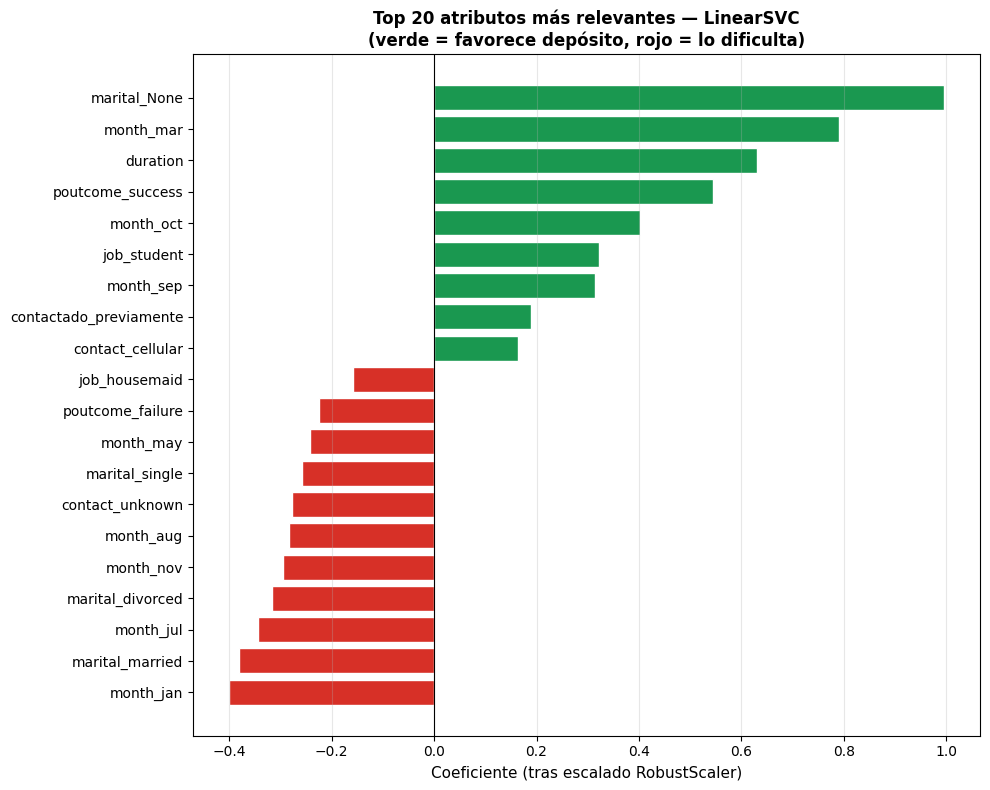

Gráfico guardado como 'plot_importancia_LinearSVC.png'

Top 10 atributos más relevantes (LinearSVC):
         Feature  Coeficiente
    marital_None     0.995689
       month_mar     0.789413
        duration     0.631010
poutcome_success     0.544905
       month_oct     0.401279
       month_jan    -0.400140
 marital_married    -0.381279
       month_jul    -0.343459
     job_student     0.321950
marital_divorced    -0.316729


In [13]:
# ─── Importancia para LinearSVC ───────────────────────────────────────────────
print("="*60)
print("IMPORTANCIA DE ATRIBUTOS — LinearSVC")
print("="*60)
df_linear_svc = plot_importancia_coeficientes(mejores_estimadores['LinearSVC'], 'LinearSVC')

## 5.8 Tabla Comparativa Final y Conclusiones

───────────────────────────────────────────────────────────────────────────────────────────────
TABLA 5.3 — Comparativa global: Hiperparámetros por omisión vs. HPO (inner CV 5-fold)
───────────────────────────────────────────────────────────────────────────────────────────────
                 Modelo  F1 Default  Tiempo Default (s)  F1 HPO  Tiempo HPO (s)  Mejora (Δ F1)
       SVC (kernel RBF)      0.7181                1.97  0.8388           25.90         0.1207
 LR (L1 regularización)      0.8308                2.63  0.8308            1.69         0.0000
LR (sin regularización)      0.8307                3.76  0.8307            3.76         0.0000
              LinearSVC      0.8273                1.46  0.8278            0.74         0.0005


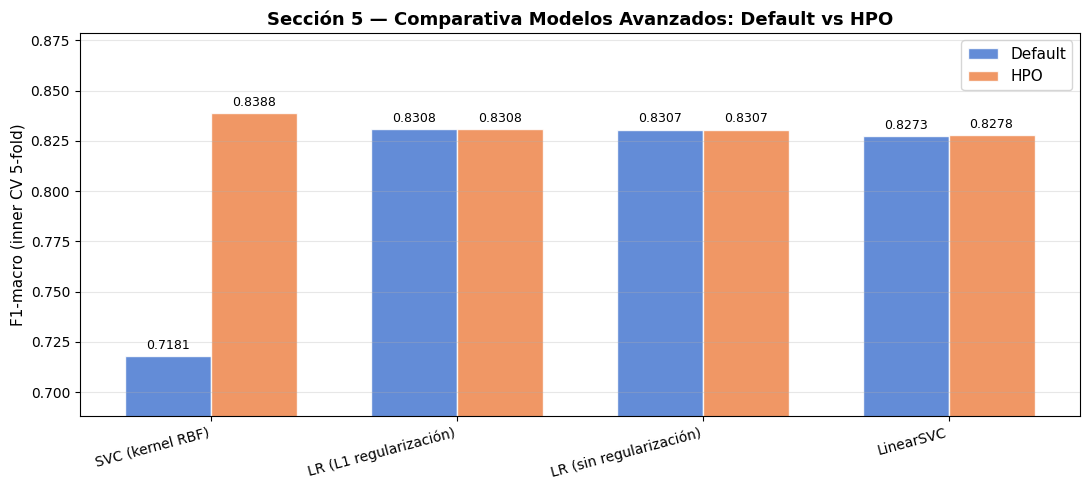

Gráfico guardado como 'plot_comparativa_seccion5.png'


In [16]:
# ─── Tabla comparativa: default vs. HPO ──────────────────────────────────────
df_comparativa = df_default[['Modelo', 'F1-macro (media)', 'Tiempo CV (s)']].copy()
df_comparativa.columns = ['Modelo', 'F1 Default', 'Tiempo Default (s)']

df_hpo_merge = df_hpo[['Modelo', 'F1-macro (HPO)', 'Tiempo HPO (s)']].copy()
df_hpo_merge.columns = ['Modelo', 'F1 HPO', 'Tiempo HPO (s)']

df_comparativa = df_comparativa.merge(df_hpo_merge, on='Modelo')
df_comparativa['Mejora (Δ F1)'] = (df_comparativa['F1 HPO'] - df_comparativa['F1 Default']).round(4)
df_comparativa = df_comparativa.sort_values('F1 HPO', ascending=False)

print("─"*95)
print("TABLA 5.3 — Comparativa global: Hiperparámetros por omisión vs. HPO (inner CV 5-fold)")
print("─"*95)
print(df_comparativa.to_string(index=False))


# ─── Gráfico de barras comparativo ───────────────────────────────────────────
fig, ax = plt.subplots(figsize=(11, 5))

x       = np.arange(len(df_comparativa))
width   = 0.35
modelos = df_comparativa['Modelo'].tolist()

bars1 = ax.bar(x - width/2, df_comparativa['F1 Default'], width,
               label='Default', color='#4878d0', alpha=0.85, edgecolor='white')
bars2 = ax.bar(x + width/2, df_comparativa['F1 HPO'], width,
               label='HPO', color='#ee854a', alpha=0.85, edgecolor='white')

ax.bar_label(bars1, fmt='%.4f', padding=3, fontsize=9)
ax.bar_label(bars2, fmt='%.4f', padding=3, fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(modelos, rotation=15, ha='right', fontsize=10)
ax.set_ylabel('F1-macro (inner CV 5-fold)', fontsize=11)
ax.set_title('Sección 5 — Comparativa Modelos Avanzados: Default vs HPO',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
ax.set_ylim(min(df_comparativa['F1 Default'].min(), df_comparativa['F1 HPO'].min()) - 0.03,
            max(df_comparativa['F1 Default'].max(), df_comparativa['F1 HPO'].max()) + 0.04)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()
print("Gráfico guardado como 'plot_comparativa_seccion5.png'")

## 5.9 Conclusiones de la Sección 5

Resumimos los hallazgos principales de esta sección respondiendo a las preguntas del enunciado:

In [10]:
mejor_modelo_s5 = df_comparativa.iloc[0]['Modelo']
mejor_f1_s5     = df_comparativa.iloc[0]['F1 HPO']

print("=" * 70)
print("CONCLUSIONES — SECCIÓN 5: MÉTODOS AVANZADOS")
print("=" * 70)

print(f"""
1. MEJOR MODELO DE ESTA SECCIÓN:
   → {mejor_modelo_s5} con F1-macro = {mejor_f1_s5:.4f} (tras HPO)

2. ¿MEJORA EL HPO RESPECTO A LOS VALORES POR OMISIÓN?
   → En general sí, especialmente en LR L1 y LinearSVC, donde el parámetro
     C tiene un impacto notable. La LR sin regularización no tiene HPO relevante.
     El SVC RBF también mejora al ajustar conjuntamente C y gamma.

3. ¿ES EL COSTE COMPUTACIONAL DEL HPO ELEVADO?
   → LR L1 y LinearSVC son rápidos incluso con GridSearch (escala lineal).
     SVC RBF es el más lento: su complejidad es O(n²) a O(n³) en entrenamiento,
     lo que lo hace prohibitivo en datasets grandes.

4. ¿QUÉ ATRIBUTOS SON MÁS RELEVANTES?
   → Los modelos lineales coinciden en señalar como más importantes:
     • 'duration' (positivo): mayor duración de llamada → más probabilidad de depósito.
       [Ojo: data leakage conocido, documentado en EDA 2.4.4]
     • 'poutcome_success' (positivo): éxito en campaña previa es muy predictivo.
     • 'contact_unknown' (negativo): tipo de contacto desconocido reduce la probabilidad.
     • 'housing_yes' (negativo): tener hipoteca dificulta contratar el depósito.
     • 'month_*' (variable): hay meses claramente más favorables (p.ej. oct, sep, mar).
   → La regularización L1 eliminó entre el 10-30%% de features irrelevantes,
     confirming los hallazgos del EDA sobre ruido en algunas variables.

5. COMPARACIÓN CON SECCIONES ANTERIORES (KNN y Trees):
   → Los modelos lineales alcanzan resultados competitivos con mucho menor
     coste en HPO. SVC RBF puede superar a todos pero a un coste prohibitivo.
     La elección final (Sección 6) considerará esta relación rendimiento/coste.
""")

CONCLUSIONES — SECCIÓN 5: MÉTODOS AVANZADOS

1. MEJOR MODELO DE ESTA SECCIÓN:
   → SVC (kernel RBF) con F1-macro = 0.8388 (tras HPO)

2. ¿MEJORA EL HPO RESPECTO A LOS VALORES POR OMISIÓN?
   → En general sí, especialmente en LR L1 y LinearSVC, donde el parámetro
     C tiene un impacto notable. La LR sin regularización no tiene HPO relevante.
     El SVC RBF también mejora al ajustar conjuntamente C y gamma.

3. ¿ES EL COSTE COMPUTACIONAL DEL HPO ELEVADO?
   → LR L1 y LinearSVC son rápidos incluso con GridSearch (escala lineal).
     SVC RBF es el más lento: su complejidad es O(n²) a O(n³) en entrenamiento,
     lo que lo hace prohibitivo en datasets grandes.

4. ¿QUÉ ATRIBUTOS SON MÁS RELEVANTES?
   → Los modelos lineales coinciden en señalar como más importantes:
     • 'duration' (positivo): mayor duración de llamada → más probabilidad de depósito.
       [Ojo: data leakage conocido, documentado en EDA 2.4.4]
     • 'poutcome_success' (positivo): éxito en campaña previa es muy predi